In [1]:
import numpy as np
import pandas as pd
import bottleneck as bn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Bottleneck:", bn.__version__)
print("All imports successful!")

Pandas: 2.3.1
NumPy: 2.3.2
Bottleneck: 1.6.0
All imports successful!


In [5]:

from pathlib import Path
import pandas as pd

# Locate the raw data folder
PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)
print("Raw directory exists:", RAW_DIR.exists())

# Find all CSV files
csv_files = sorted(RAW_DIR.glob("*.csv"))

print("\nNumber of CSV files found:", len(csv_files))

if not csv_files:
    print("No CSV files found. Check the project directory.")
else:
    for file in csv_files:
        print(file.name)

# Inspect each CSV
inventory = []

for file in csv_files:
    try:
        df = pd.read_csv(file, low_memory=False)

        inventory.append({
            "file": file.name,
            "rows": len(df),
            "columns": len(df.columns),
            "duplicate_rows": int(df.duplicated().sum()),
            "total_missing_cells": int(df.isna().sum().sum()),
            "size_mb": round(file.stat().st_size / (1024 ** 2), 2)
        })

    except Exception as e:
        print(f"\nCould not inspect {file.name}: {e}")

inventory_df = pd.DataFrame(inventory)

print("\nDATASET INVENTORY")
display(inventory_df)



Project directory: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment
Raw data directory: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\data\raw
Raw directory exists: True

Number of CSV files found: 18
account_status_history.csv
accounts.csv
agent_sessions.csv
agents.csv
borrowers.csv
call_attempts.csv
call_dispositions.csv
calls.csv
campaigns.csv
complaints.csv
daily_targeting.csv
data_dictionary.csv
field_visits.csv
payments.csv
promises_to_pay.csv
sms_events.csv
vendor_telephony.csv
whatsapp_events.csv

DATASET INVENTORY


,file,rows,columns,duplicate_rows,total_missing_cells,size_mb
0,account_status_history.csv,60000,8,0,0,5.76
1,accounts.csv,30000,11,0,455,2.76
2,agent_sessions.csv,15000,7,0,0,1.23
3,agents.csv,30000,8,0,0,2.74
4,borrowers.csv,30600,8,600,1509,3.27
5,call_attempts.csv,120000,9,0,2400,11.54
6,call_dispositions.csv,35000,8,0,0,3.26
7,calls.csv,91350,11,1271,1827,10.20
8,campaigns.csv,120,7,0,0,0.01
9,complaints.csv,8000,9,0,0,0.84


In [7]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path.cwd() / "data" / "raw"

dictionary = pd.read_csv(RAW_DIR / "data_dictionary.csv")

print("Shape:", dictionary.shape)
print("Columns:", dictionary.columns.tolist())

display(dictionary.head(30))

Shape: (143, 3)
Columns: ['dataset', 'column', 'dtype']


,dataset,column,dtype
0,borrowers,borrower_id,object
1,borrowers,name,object
2,borrowers,phone,object
3,borrowers,email,object
4,borrowers,city,object
5,borrowers,created_at,datetime64[ns]
6,borrowers,updated_at,datetime64[ns]
7,borrowers,state,object
8,accounts,account_id,object
9,accounts,borrower_id,object


In [9]:
key_columns = dictionary[
    dictionary["column"].str.contains(
        r"id|reference|code|timestamp|created_at|updated_at",
        case=False,
        na=False
    )
]

display(key_columns)

,dataset,column,dtype
0,borrowers,borrower_id,object
5,borrowers,created_at,datetime64[ns]
6,borrowers,updated_at,datetime64[ns]
8,accounts,account_id,object
9,accounts,borrower_id,object
...,...,...,...
127,complaints,account_id,object
128,complaints,borrower_id,object
135,account_status_history,history_id,object
136,account_status_history,account_id,object


In [11]:
for dataset_name, group in dictionary.groupby("dataset"):
    print(f"\n{dataset_name}")
    print(group["column"].tolist())


account_status_history
['history_id', 'account_id', 'borrower_id', 'event_at', 'status', 'changed_by', 'source', 'recorded_at']

accounts
['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

agent_sessions
['session_id', 'agent_id', 'login_at', 'channel', 'device_id', 'timezone', 'logout_at']

agents
['agent_id', 'employee_code', 'agent_name', 'vendor_id', 'team', 'status', 'joined_at', 'updated_at']

borrowers
['borrower_id', 'name', 'phone', 'email', 'city', 'created_at', 'updated_at', 'state']

call_attempts
['attempt_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'attempt_no', 'vendor_id', 'attempt_status']

call_dispositions
['disposition_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'disposition_code', 'disposition_version']

calls
['call_id', 'account_id', 'borrower_id', 'event_at', 'agent_id', 'campaign_id', 'direction', 'ven

In [16]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path.cwd() / "data" / "raw"

key_candidates = {
    "borrowers": ["borrower_id"],
    "accounts": ["account_id"],
    "agents": ["agent_id"],
    "agent_sessions": ["session_id"],
    "calls": ["call_id"],
    "call_attempts": ["attempt_id"],
    "call_dispositions": ["disposition_id"],
    "payments": ["payment_reference"],
    "promises_to_pay": ["ptp_id"],
    "field_visits": ["visit_id"],
    "sms_events": ["sms_event_id"],
    "whatsapp_events": ["whatsapp_event_id"],
    "complaints": ["complaint_id"],
    "account_status_history": ["history_id"],
    "daily_targeting": ["target_id"]
}

results = []

for dataset, keys in key_candidates.items():
    df = pd.read_csv(RAW_DIR / f"{dataset}.csv", low_memory=False)

    for key in keys:
        results.append({
            "dataset": dataset,
            "candidate_key": key,
            "total_rows": len(df),
            "missing_key": int(df[key].isna().sum()),
            "unique_values": int(df[key].nunique()),
            "duplicate_key_rows": int(df[key].duplicated(keep=False).sum()),
            "unique_key": bool(
                df[key].notna().all() and df[key].is_unique
            )
        })

key_report = pd.DataFrame(results)
display(key_report)

,dataset,candidate_key,total_rows,missing_key,unique_values,duplicate_key_rows,unique_key
0,borrowers,borrower_id,30600,0,11015,28151,False
1,accounts,account_id,30000,0,30000,0,True
2,agents,agent_id,30000,0,1000,30000,False
3,agent_sessions,session_id,15000,0,15000,0,True
4,calls,call_id,91350,0,90000,2700,False
5,call_attempts,attempt_id,120000,0,120000,0,True
6,call_dispositions,disposition_id,35000,0,35000,0,True
7,payments,payment_reference,25500,382,20821,8424,False
8,promises_to_pay,ptp_id,18000,0,18000,0,True
9,field_visits,visit_id,25000,0,25000,0,True


In [18]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path.cwd() / "data" / "raw"

payments = pd.read_csv(RAW_DIR / "payments.csv", low_memory=False)

print("Total payment rows:", len(payments))
print("Missing payment references:", payments["payment_reference"].isna().sum())
print("Unique payment references:", payments["payment_reference"].nunique())

duplicate_refs = payments[
    payments["payment_reference"].notna()
    & payments["payment_reference"].duplicated(keep=False)
].sort_values("payment_reference")

print("Rows with repeated payment references:", len(duplicate_refs))

display(duplicate_refs.head(30))

Total payment rows: 25500
Missing payment references: 382
Unique payment references: 20821
Rows with repeated payment references: 8042


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
25010,PAYMENT0000552,ACC0021942,BRW0011343,2026-08-06 18:56:06,TXN0000000009,11792.14,SUCCESS,UPI,VND0000012
551,PAYMENT0000552,ACC0021942,BRW0011343,2026-08-06 18:56:06,TXN0000000009,11792.14,SUCCESS,UPI,VND0000012
1387,PAYMENT0001388,ACC0019483,BRW0003324,2026-01-31 05:00:49,TXN0000000027,53610.92,FAILED,CARD,VND0000005
3477,PAYMENT0003478,ACC0022277,BRW0011422,2026-06-09 12:22:41,TXN0000000027,43010.39,SUCCESS,NACH,VND0000010
5306,PAYMENT0005307,ACC0003975,BRW0007408,2026-05-24 14:49:16,TXN0000000032,18086.24,PENDING,CARD,VND0000003
2884,PAYMENT0002885,ACC0021199,BRW0008425,2026-05-03 23:45:49,TXN0000000032,104969.97,SUCCESS,NACH,VND0000007
21182,PAYMENT0021183,ACC0011292,BRW0006242,2026-04-10 12:10:27,TXN0000000032,15714.97,SUCCESS,CASH,VND0000005
2839,PAYMENT0002840,ACC0022601,BRW0006594,2026-02-01 22:47:46,TXN0000000113,1139.66,SUCCESS,CARD,VND0000003
13292,PAYMENT0013293,ACC0019961,BRW0006917,2026-01-17 20:51:05,TXN0000000113,55554.44,REVERSED,CARD,VND0000007
18917,PAYMENT0018918,ACC0012876,BRW0010206,2026-08-03 02:17:02,TXN0000000113,101681.86,SUCCESS,CARD,VND0000010


In [20]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path.cwd() / "data" / "raw"

payments = pd.read_csv(RAW_DIR / "payments.csv", low_memory=False)

exact_duplicates = payments[
    payments.duplicated(keep=False)
].sort_values(list(payments.columns))

print("Total payment rows:", len(payments))
print("Rows involved in exact duplicate groups:", len(exact_duplicates))
print("Extra rows removable by exact deduplication:", payments.duplicated().sum())

display(exact_duplicates.head(20))

Total payment rows: 25500
Rows involved in exact duplicate groups: 972
Extra rows removable by exact deduplication: 486


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
55,PAYMENT0000056,ACC0019495,BRW0009716,2026-02-24 09:33:29,TXN0000008612,77982.73,PENDING,NETBANKING,VND0000007
25035,PAYMENT0000056,ACC0019495,BRW0009716,2026-02-24 09:33:29,TXN0000008612,77982.73,PENDING,NETBANKING,VND0000007
75,PAYMENT0000076,ACC0027928,BRW0010869,2026-02-05 17:14:30,TXN0000006417,43712.91,PENDING,UPI,VND0000014
25408,PAYMENT0000076,ACC0027928,BRW0010869,2026-02-05 17:14:30,TXN0000006417,43712.91,PENDING,UPI,VND0000014
107,PAYMENT0000108,ACC0017047,BRW0009175,2026-06-09 08:17:45,TXN0000041404,102830.42,SUCCESS,NACH,VND0000003
25481,PAYMENT0000108,ACC0017047,BRW0009175,2026-06-09 08:17:45,TXN0000041404,102830.42,SUCCESS,NACH,VND0000003
148,PAYMENT0000149,ACC0018444,BRW0005741,2026-07-25 03:04:14,TXN0000066565,96766.12,SUCCESS,CASH,VND0000013
25099,PAYMENT0000149,ACC0018444,BRW0005741,2026-07-25 03:04:14,TXN0000066565,96766.12,SUCCESS,CASH,VND0000013
198,PAYMENT0000199,ACC0000056,BRW0001872,2026-05-12 22:49:22,TXN0000069967,81814.00,SUCCESS,NETBANKING,VND0000012
25330,PAYMENT0000199,ACC0000056,BRW0001872,2026-05-12 22:49:22,TXN0000069967,81814.00,SUCCESS,NETBANKING,VND0000012


In [22]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path.cwd() / "data" / "raw"

payments = pd.read_csv(RAW_DIR / "payments.csv", low_memory=False)

deduplicated = payments.drop_duplicates().copy()

payments["amount"] = pd.to_numeric(payments["amount"], errors="coerce")
deduplicated["amount"] = pd.to_numeric(deduplicated["amount"], errors="coerce")

print("Original rows:", len(payments))
print("Rows after exact deduplication:", len(deduplicated))
print("Rows removed:", len(payments) - len(deduplicated))

print("\nOriginal payment status totals:")
display(
    payments.groupby("payment_status")["amount"]
    .agg(["count", "sum"])
    .round(2)
)

print("\nDeduplicated payment status totals:")
display(
    deduplicated.groupby("payment_status")["amount"]
    .agg(["count", "sum"])
    .round(2)
)

successful_before = payments.loc[
    payments["payment_status"].eq("SUCCESS"), "amount"
].sum()

successful_after = deduplicated.loc[
    deduplicated["payment_status"].eq("SUCCESS"), "amount"
].sum()

print("\nSuccessful payment amount before deduplication:", round(successful_before, 2))
print("Successful payment amount after deduplication:", round(successful_after, 2))
print("Potential duplicate-related overstatement:", round(successful_before - successful_after, 2))

Original rows: 25500
Rows after exact deduplication: 25014
Rows removed: 486

Original payment status totals:


,count,sum
payment_status,,
FAILED,3744,2.835063e+08
PENDING,2592,1.948680e+08
REVERSED,1284,9.739842e+07
SUCCESS,17880,1.341486e+09



Deduplicated payment status totals:


,count,sum
payment_status,,
FAILED,3678,2.784453e+08
PENDING,2536,1.903653e+08
REVERSED,1255,9.467448e+07
SUCCESS,17545,1.316474e+09



Successful payment amount before deduplication: 1341485926.33
Successful payment amount after deduplication: 1316474464.14
Potential duplicate-related overstatement: 25011462.19


In [24]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path.cwd() / "data" / "raw"

payments = pd.read_csv(RAW_DIR / "payments.csv", low_memory=False)
payments = payments.drop_duplicates()

valid_refs = payments[payments["payment_reference"].notna()].copy()

reference_report = valid_refs.groupby("payment_reference").agg(
    row_count=("payment_id", "size"),
    payment_ids=("payment_id", "nunique"),
    accounts=("account_id", "nunique"),
    amounts=("amount", "nunique"),
    statuses=("payment_status", "nunique"),
    providers=("provider_id", "nunique")
).reset_index()

reference_collisions = reference_report[
    (reference_report["row_count"] > 1)
    & (
        (reference_report["payment_ids"] > 1)
        | (reference_report["accounts"] > 1)
        | (reference_report["amounts"] > 1)
        | (reference_report["statuses"] > 1)
        | (reference_report["providers"] > 1)
    )
]

print("Unique non-missing references:", len(reference_report))
print("References used by multiple records:", (reference_report["row_count"] > 1).sum())
print("References with conflicting transaction details:", len(reference_collisions))

display(
    reference_collisions.sort_values(
        "row_count", ascending=False
    ).head(20)
)

Unique non-missing references: 20821
References used by multiple records: 3407
References with conflicting transaction details: 3407


,payment_reference,row_count,payment_ids,accounts,amounts,statuses,providers
13081,TXN0000044312,5,5,5,5,2,3
1993,TXN0000006936,4,4,4,4,3,3
2728,TXN0000009490,4,4,4,4,1,4
6280,TXN0000021482,4,4,4,4,2,4
5835,TXN0000020022,4,4,4,4,3,4
3446,TXN0000011850,4,4,4,4,2,3
20690,TXN0000069582,4,4,4,4,3,4
5895,TXN0000020227,4,4,4,4,1,3
515,TXN0000001778,4,4,4,4,2,3
3869,TXN0000013291,4,4,4,4,2,4


In [26]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path.cwd() / "data" / "raw"

payments = pd.read_csv(RAW_DIR / "payments.csv", low_memory=False)
payments = payments.drop_duplicates()

payments["amount"] = pd.to_numeric(
    payments["amount"], errors="coerce"
)

status_summary = payments.groupby("payment_status").agg(
    records=("payment_id", "size"),
    unique_payment_ids=("payment_id", "nunique"),
    unique_accounts=("account_id", "nunique"),
    amount_total=("amount", "sum")
).reset_index()

display(status_summary.round(2))

successful = payments[payments["payment_status"].eq("SUCCESS")].copy()
reversed_payments = payments[payments["payment_status"].eq("REVERSED")].copy()

print("Successful records:", len(successful))
print("Reversed records:", len(reversed_payments))

print("Successful payment IDs:", successful["payment_id"].nunique())
print("Reversed payment IDs:", reversed_payments["payment_id"].nunique())

print("Successful payment amount:", round(successful["amount"].sum(), 2))
print("Reversed payment amount:", round(reversed_payments["amount"].sum(), 2))

,payment_status,records,unique_payment_ids,unique_accounts,amount_total
0,FAILED,3678,3677,3443,2.784453e+08
1,PENDING,2536,2535,2430,1.903653e+08
2,REVERSED,1255,1254,1230,9.467448e+07
3,SUCCESS,17545,17534,13284,1.316474e+09


Successful records: 17545
Reversed records: 1255
Successful payment IDs: 17534
Reversed payment IDs: 1254
Successful payment amount: 1316474464.14
Reversed payment amount: 94674480.81


In [28]:
payment_id_summary = payments.groupby("payment_id").agg(
    record_count=("payment_id", "size"),
    accounts=("account_id", "nunique"),
    borrowers=("borrower_id", "nunique"),
    amounts=("amount", "nunique"),
    statuses=("payment_status", "nunique"),
    references=("payment_reference", "nunique"),
    providers=("provider_id", "nunique")
).reset_index()

duplicate_payment_ids = payment_id_summary[
    payment_id_summary["record_count"] > 1
].copy()

print("Unique payment IDs:", payments["payment_id"].nunique())
print("Payment IDs appearing multiple times:", len(duplicate_payment_ids))
print("Extra records beyond one per payment ID:", duplicate_payment_ids["record_count"].sum() - len(duplicate_payment_ids))
print("IDs with multiple accounts:", (duplicate_payment_ids["accounts"] > 1).sum())
print("IDs with multiple amounts:", (duplicate_payment_ids["amounts"] > 1).sum())
print("IDs with multiple statuses:", (duplicate_payment_ids["statuses"] > 1).sum())
print("IDs with multiple references:", (duplicate_payment_ids["references"] > 1).sum())

display(
    duplicate_payment_ids.sort_values(
        "record_count", ascending=False
    ).head(20)
)

Unique payment IDs: 25000
Payment IDs appearing multiple times: 14
Extra records beyond one per payment ID: 14
IDs with multiple accounts: 0
IDs with multiple amounts: 0
IDs with multiple statuses: 0
IDs with multiple references: 0


,payment_id,record_count,accounts,borrowers,amounts,statuses,references,providers
1389,PAYMENT0001390,2,1,1,1,1,1,1
2097,PAYMENT0002098,2,1,1,1,1,1,1
2302,PAYMENT0002303,2,1,1,1,1,1,1
5190,PAYMENT0005191,2,1,1,1,1,1,1
7581,PAYMENT0007582,2,1,1,1,1,1,1
7750,PAYMENT0007751,2,1,1,1,1,1,1
8751,PAYMENT0008752,2,1,1,1,1,1,1
10557,PAYMENT0010558,2,1,1,1,1,1,1
16861,PAYMENT0016862,2,1,1,1,1,1,1
18133,PAYMENT0018134,2,1,1,1,1,1,1


In [30]:
repeated_ids = duplicate_payment_ids["payment_id"]

repeated_payment_records = payments[
    payments["payment_id"].isin(repeated_ids)
].sort_values("payment_id")

display(repeated_payment_records)

,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
1389,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59,TXN0000046535,85205.16,SUCCESS,CASH,VND0000015
25043,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59,NaN,85205.16,SUCCESS,CASH,VND0000015
2097,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16,TXN0000001302,5570.92,SUCCESS,NETBANKING,VND0000001
25055,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16,NaN,5570.92,SUCCESS,NETBANKING,VND0000001
2302,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47,TXN0000067311,59429.86,SUCCESS,CARD,VND0000011
25057,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47,NaN,59429.86,SUCCESS,CARD,VND0000011
25437,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03,TXN0000041890,107235.47,SUCCESS,NACH,VND0000002
5190,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03,NaN,107235.47,SUCCESS,NACH,VND0000002
25385,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42,TXN0000013106,119714.20,SUCCESS,NETBANKING,VND0000014
7581,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42,NaN,119714.20,SUCCESS,NETBANKING,VND0000014


In [32]:
payment_comparison = payments[
    payments["payment_id"].isin(duplicate_payment_ids["payment_id"])
].copy()

comparison_columns = [
    "account_id",
    "borrower_id",
    "event_at",
    "payment_reference",
    "amount",
    "payment_status",
    "payment_method",
    "provider_id"
]

payment_comparison["missing_reference"] = payment_comparison["payment_reference"].isna()

comparison_summary = payment_comparison.groupby("payment_id").agg(
    record_count=("payment_id", "size"),
    missing_references=("missing_reference", "sum"),
    unique_accounts=("account_id", "nunique"),
    unique_borrowers=("borrower_id", "nunique"),
    unique_timestamps=("event_at", "nunique"),
    unique_amounts=("amount", "nunique"),
    unique_statuses=("payment_status", "nunique"),
    unique_methods=("payment_method", "nunique"),
    unique_providers=("provider_id", "nunique")
).reset_index()

display(comparison_summary)


,payment_id,record_count,missing_references,unique_accounts,unique_borrowers,unique_timestamps,unique_amounts,unique_statuses,unique_methods,unique_providers
0,PAYMENT0001390,2,1,1,1,1,1,1,1,1
1,PAYMENT0002098,2,1,1,1,1,1,1,1,1
2,PAYMENT0002303,2,1,1,1,1,1,1,1,1
3,PAYMENT0005191,2,1,1,1,1,1,1,1,1
4,PAYMENT0007582,2,1,1,1,1,1,1,1,1
5,PAYMENT0007751,2,1,1,1,1,1,1,1,1
6,PAYMENT0008752,2,1,1,1,1,1,1,1,1
7,PAYMENT0010558,2,1,1,1,1,1,1,1,1
8,PAYMENT0016862,2,1,1,1,1,1,1,1,1
9,PAYMENT0018134,2,1,1,1,1,1,1,1,1


In [34]:
payment_completeness = payments[
    payments["payment_id"].isin(duplicate_payment_ids["payment_id"])
].copy()

payment_completeness["filled_fields"] = payment_completeness.notna().sum(axis=1)

payment_completeness = payment_completeness.sort_values(
    ["payment_id", "filled_fields"],
    ascending=[True, False]
)

display(
    payment_completeness[
        payment_completeness["payment_id"].duplicated(keep=False)
    ]
)

,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id,filled_fields
1389,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59,TXN0000046535,85205.16,SUCCESS,CASH,VND0000015,9
25043,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59,NaN,85205.16,SUCCESS,CASH,VND0000015,8
2097,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16,TXN0000001302,5570.92,SUCCESS,NETBANKING,VND0000001,9
25055,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16,NaN,5570.92,SUCCESS,NETBANKING,VND0000001,8
2302,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47,TXN0000067311,59429.86,SUCCESS,CARD,VND0000011,9
25057,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47,NaN,59429.86,SUCCESS,CARD,VND0000011,8
25437,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03,TXN0000041890,107235.47,SUCCESS,NACH,VND0000002,9
5190,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03,NaN,107235.47,SUCCESS,NACH,VND0000002,8
25385,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42,TXN0000013106,119714.20,SUCCESS,NETBANKING,VND0000014,9
7581,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42,NaN,119714.20,SUCCESS,NETBANKING,VND0000014,8


In [36]:
duplicate_check = payments[
    payments["payment_id"].isin(duplicate_payment_ids["payment_id"])
].copy()

comparison_results = []

for payment_id, group in duplicate_check.groupby("payment_id"):
    comparison_results.append({
        "payment_id": payment_id,
        "record_count": len(group),
        "different_columns": [
            col for col in payments.columns
            if group[col].nunique(dropna=False) > 1
        ]
    })

duplicate_validation = pd.DataFrame(comparison_results)

display(duplicate_validation)

,payment_id,record_count,different_columns
0,PAYMENT0001390,2,[payment_reference]
1,PAYMENT0002098,2,[payment_reference]
2,PAYMENT0002303,2,[payment_reference]
3,PAYMENT0005191,2,[payment_reference]
4,PAYMENT0007582,2,[payment_reference]
5,PAYMENT0007751,2,[payment_reference]
6,PAYMENT0008752,2,[payment_reference]
7,PAYMENT0010558,2,[payment_reference]
8,PAYMENT0016862,2,[payment_reference]
9,PAYMENT0018134,2,[payment_reference]


In [38]:
payments_clean = payments.copy()

payments_clean["_original_order"] = range(len(payments_clean))

payments_clean = payments_clean.sort_values(
    ["payment_id", "payment_reference", "_original_order"],
    ascending=[True, False, True],
    na_position="last"
)

payments_clean = payments_clean.drop_duplicates(
    subset=["payment_id"],
    keep="first"
)

payments_clean = payments_clean.drop(
    columns=["_original_order"]
).reset_index(drop=True)

print("Original payment rows:", len(payments))
print("Cleaned payment rows:", len(payments_clean))
print("Rows removed:", len(payments) - len(payments_clean))
print("Remaining unique payment IDs:", payments_clean["payment_id"].nunique())
print("Missing payment references after cleaning:", payments_clean["payment_reference"].isna().sum())

Original payment rows: 25014
Cleaned payment rows: 25000
Rows removed: 14
Remaining unique payment IDs: 25000
Missing payment references after cleaning: 368


In [40]:
missing_ref = payments_clean[
    payments_clean["payment_reference"].isna()
].copy()

print("Missing payment references:", len(missing_ref))
print("Unique payment IDs:", missing_ref["payment_id"].nunique())
print("Payment statuses:")
display(missing_ref["payment_status"].value_counts(dropna=False).to_frame("count"))

print("Sample records:")
display(missing_ref.head(15))

Missing payment references: 368
Unique payment IDs: 368
Payment statuses:


,count
payment_status,
SUCCESS,254
FAILED,54
PENDING,38
REVERSED,22


Sample records:


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
12,PAYMENT0000013,ACC0026504,BRW0009822,2026-05-06 22:30:42,NaN,41543.11,SUCCESS,CARD,VND0000013
153,PAYMENT0000154,ACC0024849,BRW0009430,2026-04-02 22:17:21,NaN,73382.67,FAILED,UPI,VND0000005
189,PAYMENT0000190,ACC0008922,BRW0010315,2026-08-04 06:05:43,NaN,39739.80,SUCCESS,NACH,VND0000011
210,PAYMENT0000211,ACC0011320,BRW0004951,2026-07-30 11:36:50,NaN,18417.58,SUCCESS,CASH,VND0000001
276,PAYMENT0000277,ACC0012078,BRW0009370,2026-05-26 16:27:17,NaN,103032.48,SUCCESS,NETBANKING,VND0000010
413,PAYMENT0000414,ACC0029253,BRW0008819,2026-01-15 16:40:04,NaN,131125.68,SUCCESS,CASH,VND0000014
446,PAYMENT0000447,ACC0015233,BRW0009862,2026-04-26 23:17:16,NaN,93762.91,PENDING,UPI,VND0000003
513,PAYMENT0000514,ACC0013461,BRW0011267,2026-08-06 09:06:35,NaN,29075.40,FAILED,UPI,VND0000002
539,PAYMENT0000540,ACC0028470,BRW0002140,2026-06-11 11:25:18,NaN,89925.12,SUCCESS,CARD,VND0000009
554,PAYMENT0000555,ACC0026518,BRW0000130,2026-04-29 18:44:23,NaN,12072.89,PENDING,NETBANKING,VND0000001


In [42]:
payment_reference_map = (
    payments.dropna(subset=["payment_reference"])
    .drop_duplicates(subset=["payment_id"])
    .set_index("payment_id")["payment_reference"]
)

missing_ref["recovered_reference"] = missing_ref["payment_id"].map(
    payment_reference_map
)

print("Missing references:", len(missing_ref))
print("Recoverable references:", missing_ref["recovered_reference"].notna().sum())
print("Unrecoverable references:", missing_ref["recovered_reference"].isna().sum())

display(
    missing_ref[
        ["payment_id", "payment_reference", "recovered_reference", "amount", "payment_status"]
    ].head(20)
)

Missing references: 368
Recoverable references: 0
Unrecoverable references: 368


,payment_id,payment_reference,recovered_reference,amount,payment_status
12,PAYMENT0000013,NaN,NaN,41543.11,SUCCESS
153,PAYMENT0000154,NaN,NaN,73382.67,FAILED
189,PAYMENT0000190,NaN,NaN,39739.80,SUCCESS
210,PAYMENT0000211,NaN,NaN,18417.58,SUCCESS
276,PAYMENT0000277,NaN,NaN,103032.48,SUCCESS
413,PAYMENT0000414,NaN,NaN,131125.68,SUCCESS
446,PAYMENT0000447,NaN,NaN,93762.91,PENDING
513,PAYMENT0000514,NaN,NaN,29075.40,FAILED
539,PAYMENT0000540,NaN,NaN,89925.12,SUCCESS
554,PAYMENT0000555,NaN,NaN,12072.89,PENDING


In [44]:
missing_payment_analysis = (
    payments_clean[payments_clean["payment_reference"].isna()]
    .groupby("payment_status")
    .agg(
        records=("payment_id", "size"),
        unique_accounts=("account_id", "nunique"),
        unique_borrowers=("borrower_id", "nunique"),
        total_amount=("amount", "sum"),
        missing_amounts=("amount", lambda x: x.isna().sum()),
        unique_providers=("provider_id", "nunique")
    )
    .reset_index()
)

display(missing_payment_analysis.round(2))

print("Total missing-reference records:", len(missing_ref))
print("Duplicate payment IDs:", missing_ref["payment_id"].duplicated().sum())
print("Missing account IDs:", missing_ref["account_id"].isna().sum())
print("Missing borrower IDs:", missing_ref["borrower_id"].isna().sum())
print("Missing timestamps:", missing_ref["event_at"].isna().sum())
print("Missing amounts:", missing_ref["amount"].isna().sum())

,payment_status,records,unique_accounts,unique_borrowers,total_amount,missing_amounts,unique_providers
0,FAILED,54,54,54,4347703.22,0,15
1,PENDING,38,38,38,2861846.51,0,15
2,REVERSED,22,22,22,1605962.46,0,13
3,SUCCESS,254,252,253,18873951.93,0,15


Total missing-reference records: 368
Duplicate payment IDs: 0
Missing account IDs: 0
Missing borrower IDs: 0
Missing timestamps: 0
Missing amounts: 0


In [46]:
reference_audit = (
    payments_clean.dropna(subset=["payment_reference"])
    .groupby("payment_reference")
    .agg(
        record_count=("payment_id", "size"),
        payment_ids=("payment_id", "nunique"),
        accounts=("account_id", "nunique"),
        borrowers=("borrower_id", "nunique"),
        amounts=("amount", "nunique"),
        statuses=("payment_status", "nunique"),
        providers=("provider_id", "nunique")
    )
    .reset_index()
)

conflicting_references = reference_audit[
    (reference_audit["payment_ids"] > 1) |
    (reference_audit["accounts"] > 1) |
    (reference_audit["amounts"] > 1)
].copy()

print("Unique non-missing references:", len(reference_audit))
print("Conflicting references:", len(conflicting_references))

display(
    conflicting_references.sort_values(
        ["payment_ids", "accounts", "amounts"],
        ascending=False
    ).head(20)
)

Unique non-missing references: 20821
Conflicting references: 3407


,payment_reference,record_count,payment_ids,accounts,borrowers,amounts,statuses,providers
13081,TXN0000044312,5,5,5,5,5,2,3
515,TXN0000001778,4,4,4,4,4,2,3
585,TXN0000002005,4,4,4,4,4,4,4
1993,TXN0000006936,4,4,4,4,4,3,3
2728,TXN0000009490,4,4,4,4,4,1,4
3446,TXN0000011850,4,4,4,4,4,2,3
3869,TXN0000013291,4,4,4,4,4,2,4
5835,TXN0000020022,4,4,4,4,4,3,4
5895,TXN0000020227,4,4,4,4,4,1,3
6280,TXN0000021482,4,4,4,4,4,2,4


In [48]:
sample_reference = "TXN0000044312"

display(
    payments_clean[
        payments_clean["payment_reference"] == sample_reference
    ].sort_values("event_at")
)

,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
22912,PAYMENT0022913,ACC0025320,BRW0008750,2026-01-02 14:34:45,TXN0000044312,125333.52,SUCCESS,NETBANKING,VND0000007
12956,PAYMENT0012957,ACC0025419,BRW0006475,2026-03-17 20:29:49,TXN0000044312,4943.80,SUCCESS,CARD,VND0000015
15119,PAYMENT0015120,ACC0008230,BRW0004237,2026-03-19 06:17:38,TXN0000044312,82139.32,SUCCESS,NACH,VND0000011
11734,PAYMENT0011735,ACC0021560,BRW0005868,2026-05-11 00:30:09,TXN0000044312,61143.84,FAILED,UPI,VND0000011
19781,PAYMENT0019782,ACC0008440,BRW0001094,2026-07-30 14:18:01,TXN0000044312,98129.03,SUCCESS,NETBANKING,VND0000011


In [50]:
reference_provider_audit = (
    payments_clean.dropna(subset=["payment_reference"])
    .groupby(["provider_id", "payment_reference"])
    .agg(
        record_count=("payment_id", "size"),
        unique_payment_ids=("payment_id", "nunique"),
        unique_accounts=("account_id", "nunique"),
        unique_amounts=("amount", "nunique"),
        unique_statuses=("payment_status", "nunique")
    )
    .reset_index()
)

provider_conflicts = reference_provider_audit[
    (reference_provider_audit["unique_payment_ids"] > 1) |
    (reference_provider_audit["unique_accounts"] > 1) |
    (reference_provider_audit["unique_amounts"] > 1)
]

print("Conflicting provider-reference groups:", len(provider_conflicts))

display(
    provider_conflicts.sort_values(
        ["unique_payment_ids", "unique_amounts"],
        ascending=False
    ).head(20)
)

Conflicting provider-reference groups: 291


,provider_id,payment_reference,record_count,unique_payment_ids,unique_accounts,unique_amounts,unique_statuses
2684,VND0000002,TXN0000044622,3,3,3,3,2
10637,VND0000007,TXN0000037402,3,3,3,3,2
17304,VND0000011,TXN0000044312,3,3,3,3,2
20794,VND0000013,TXN0000054308,3,3,3,3,2
20908,VND0000013,TXN0000059686,3,3,3,3,3
23,VND0000001,TXN0000000965,2,2,2,2,2
80,VND0000001,TXN0000003112,2,2,2,2,1
202,VND0000001,TXN0000008246,2,2,2,2,1
236,VND0000001,TXN0000009664,2,2,2,2,1
237,VND0000001,TXN0000009714,2,2,2,2,2


In [52]:
# Check how many providers use each payment reference

reference_provider_counts = (
    payments_clean.dropna(subset=["payment_reference"])
    .groupby("payment_reference")
    .agg(
        record_count=("payment_id", "size"),
        unique_providers=("provider_id", "nunique"),
        unique_payment_ids=("payment_id", "nunique"),
        unique_accounts=("account_id", "nunique"),
        unique_amounts=("amount", "nunique")
    )
    .reset_index()
)

# References used by multiple providers
multi_provider_references = reference_provider_counts[
    reference_provider_counts["unique_providers"] > 1
]

print(
    "References used by multiple providers:",
    len(multi_provider_references)
)

display(
    multi_provider_references.sort_values(
        "unique_providers", ascending=False
    ).head(20)
)

References used by multiple providers: 3207


,payment_reference,record_count,unique_providers,unique_payment_ids,unique_accounts,unique_amounts
6280,TXN0000021482,4,4,4,4,4
585,TXN0000002005,4,4,4,4,4
2728,TXN0000009490,4,4,4,4,4
5835,TXN0000020022,4,4,4,4,4
20690,TXN0000069582,4,4,4,4,4
7451,TXN0000025345,4,4,4,4,4
8205,TXN0000027954,4,4,4,4,4
3869,TXN0000013291,4,4,4,4,4
11540,TXN0000039096,4,4,4,4,4
13088,TXN0000044341,4,4,4,4,4


In [54]:
provider_reference_check = (
    payments_clean.dropna(subset=["payment_reference", "provider_id"])
    .groupby(["provider_id", "payment_reference"])
    .agg(
        record_count=("payment_id", "size"),
        unique_payment_ids=("payment_id", "nunique"),
        unique_accounts=("account_id", "nunique"),
        unique_amounts=("amount", "nunique"),
        unique_statuses=("payment_status", "nunique")
    )
    .reset_index()
)

same_provider_conflicts = provider_reference_check[
    (provider_reference_check["record_count"] > 1) &
    (
        (provider_reference_check["unique_payment_ids"] > 1) |
        (provider_reference_check["unique_accounts"] > 1) |
        (provider_reference_check["unique_amounts"] > 1) |
        (provider_reference_check["unique_statuses"] > 1)
    )
]

print("Conflicting provider-reference groups:", len(same_provider_conflicts))
display(same_provider_conflicts.head(20))

Conflicting provider-reference groups: 291


,provider_id,payment_reference,record_count,unique_payment_ids,unique_accounts,unique_amounts,unique_statuses
23,VND0000001,TXN0000000965,2,2,2,2,2
80,VND0000001,TXN0000003112,2,2,2,2,1
202,VND0000001,TXN0000008246,2,2,2,2,1
236,VND0000001,TXN0000009664,2,2,2,2,1
237,VND0000001,TXN0000009714,2,2,2,2,2
508,VND0000001,TXN0000021928,2,2,2,2,2
602,VND0000001,TXN0000025559,2,2,2,2,2
611,VND0000001,TXN0000026018,2,2,2,2,1
634,VND0000001,TXN0000026930,2,2,2,2,2
696,VND0000001,TXN0000029607,2,2,2,2,2


In [56]:
display(
    payments_clean[
        payments_clean.duplicated("payment_id", keep=False)
    ].sort_values("payment_id")
)

,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id


In [58]:
missing_ref_payments = payments_clean[
    payments_clean["payment_reference"].isna()
].copy()

print("Missing-reference records:", len(missing_ref_payments))
print("Unique payment IDs:", missing_ref_payments["payment_id"].nunique())
print("Unique accounts:", missing_ref_payments["account_id"].nunique())
print("Unique borrowers:", missing_ref_payments["borrower_id"].nunique())

display(
    missing_ref_payments["payment_status"]
    .value_counts()
    .rename_axis("payment_status")
    .reset_index(name="count")
)

display(missing_ref_payments.head(10))

Missing-reference records: 368
Unique payment IDs: 368
Unique accounts: 366
Unique borrowers: 365


,payment_status,count
0,SUCCESS,254
1,FAILED,54
2,PENDING,38
3,REVERSED,22


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
12,PAYMENT0000013,ACC0026504,BRW0009822,2026-05-06 22:30:42,NaN,41543.11,SUCCESS,CARD,VND0000013
153,PAYMENT0000154,ACC0024849,BRW0009430,2026-04-02 22:17:21,NaN,73382.67,FAILED,UPI,VND0000005
189,PAYMENT0000190,ACC0008922,BRW0010315,2026-08-04 06:05:43,NaN,39739.80,SUCCESS,NACH,VND0000011
210,PAYMENT0000211,ACC0011320,BRW0004951,2026-07-30 11:36:50,NaN,18417.58,SUCCESS,CASH,VND0000001
276,PAYMENT0000277,ACC0012078,BRW0009370,2026-05-26 16:27:17,NaN,103032.48,SUCCESS,NETBANKING,VND0000010
413,PAYMENT0000414,ACC0029253,BRW0008819,2026-01-15 16:40:04,NaN,131125.68,SUCCESS,CASH,VND0000014
446,PAYMENT0000447,ACC0015233,BRW0009862,2026-04-26 23:17:16,NaN,93762.91,PENDING,UPI,VND0000003
513,PAYMENT0000514,ACC0013461,BRW0011267,2026-08-06 09:06:35,NaN,29075.40,FAILED,UPI,VND0000002
539,PAYMENT0000540,ACC0028470,BRW0002140,2026-06-11 11:25:18,NaN,89925.12,SUCCESS,CARD,VND0000009
554,PAYMENT0000555,ACC0026518,BRW0000130,2026-04-29 18:44:23,NaN,12072.89,PENDING,NETBANKING,VND0000001


In [87]:
borrowers = pd.read_csv("data/raw/borrowers.csv")
accounts = pd.read_csv("data/raw/accounts.csv")

borrower_ids = set(borrowers["borrower_id"].dropna())
account_ids = set(accounts["account_id"].dropna())

payments_clean["borrower_exists"] = payments_clean["borrower_id"].isin(borrower_ids)
payments_clean["account_exists"] = payments_clean["account_id"].isin(account_ids)

print("Total payment records:", len(payments_clean))
print("Unmatched borrower IDs:", (~payments_clean["borrower_exists"]).sum())
print("Unmatched account IDs:", (~payments_clean["account_exists"]).sum())

display(
    payments_clean[
        (~payments_clean["borrower_exists"]) |
        (~payments_clean["account_exists"])
    ].head(20)
)

Total payment records: 25000
Unmatched borrower IDs: 2043
Unmatched account IDs: 0


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id,borrower_exists,account_exists
30,PAYMENT0000031,ACC0006749,BRW0010349,2026-07-07 16:36:43,TXN0000022660,16764.69,SUCCESS,NETBANKING,VND0000003,False,True
56,PAYMENT0000057,ACC0019516,BRW0007566,2026-03-09 21:17:19,TXN0000041848,125614.94,SUCCESS,NETBANKING,VND0000009,False,True
84,PAYMENT0000085,ACC0008904,BRW0002796,2026-05-19 15:32:03,TXN0000069720,142447.04,PENDING,NACH,VND0000014,False,True
114,PAYMENT0000115,ACC0021164,BRW0006708,2026-07-04 14:25:01,TXN0000025858,28357.11,SUCCESS,CASH,VND0000003,False,True
124,PAYMENT0000125,ACC0014112,BRW0005931,2026-03-18 04:53:34,TXN0000062170,24816.58,FAILED,CARD,VND0000012,False,True
129,PAYMENT0000130,ACC0010924,BRW0007950,2026-07-05 03:07:17,TXN0000054519,10714.46,SUCCESS,UPI,VND0000010,False,True
131,PAYMENT0000132,ACC0020395,BRW0001156,2026-03-14 22:04:25,TXN0000035347,138332.20,SUCCESS,CASH,VND0000006,False,True
152,PAYMENT0000153,ACC0028115,BRW0006986,2026-03-09 04:29:52,TXN0000024033,47454.26,SUCCESS,CARD,VND0000010,False,True
155,PAYMENT0000156,ACC0007678,BRW0005482,2026-04-20 01:52:31,TXN0000034637,103612.23,FAILED,NETBANKING,VND0000001,False,True
178,PAYMENT0000179,ACC0012647,BRW0010646,2026-04-14 01:10:07,TXN0000061198,121328.43,SUCCESS,CARD,VND0000002,False,True


In [89]:
unmatched_borrowers = payments_clean[
    ~payments_clean["borrower_exists"]
]

print("Unmatched borrower records:", len(unmatched_borrowers))
print("Unique unmatched borrower IDs:", unmatched_borrowers["borrower_id"].nunique())

display(
    unmatched_borrowers["borrower_id"]
    .value_counts()
    .head(20)
)

display(
    unmatched_borrowers[
        ["payment_id", "account_id", "borrower_id", "payment_status"]
    ].head(20)
)

Unmatched borrower records: 2043
Unique unmatched borrower IDs: 846


borrower_id
BRW0000515    7
BRW0011403    7
BRW0006737    7
BRW0009875    7
BRW0002244    7
BRW0001577    6
BRW0001567    6
BRW0009183    6
BRW0011854    6
BRW0011790    6
BRW0011268    6
BRW0009996    6
BRW0011934    6
BRW0008162    6
BRW0009520    6
BRW0007496    6
BRW0001737    6
BRW0003154    6
BRW0002569    5
BRW0001156    5
Name: count, dtype: int64

,payment_id,account_id,borrower_id,payment_status
30,PAYMENT0000031,ACC0006749,BRW0010349,SUCCESS
56,PAYMENT0000057,ACC0019516,BRW0007566,SUCCESS
84,PAYMENT0000085,ACC0008904,BRW0002796,PENDING
114,PAYMENT0000115,ACC0021164,BRW0006708,SUCCESS
124,PAYMENT0000125,ACC0014112,BRW0005931,FAILED
129,PAYMENT0000130,ACC0010924,BRW0007950,SUCCESS
131,PAYMENT0000132,ACC0020395,BRW0001156,SUCCESS
152,PAYMENT0000153,ACC0028115,BRW0006986,SUCCESS
155,PAYMENT0000156,ACC0007678,BRW0005482,FAILED
178,PAYMENT0000179,ACC0012647,BRW0010646,SUCCESS


In [91]:
account_borrower_check = accounts[
    ~accounts["borrower_id"].isin(borrower_ids)
]

print("Total accounts:", len(accounts))
print("Accounts with unmatched borrower IDs:", len(account_borrower_check))
print("Unique unmatched borrower IDs:", account_borrower_check["borrower_id"].nunique())

display(
    account_borrower_check[
        ["account_id", "borrower_id"]
    ].head(20)
)

Total accounts: 30000
Accounts with unmatched borrower IDs: 2913
Unique unmatched borrower IDs: 897


,account_id,borrower_id
5,ACC0000006,NaN
7,ACC0000008,BRW0011565
14,ACC0000015,NaN
42,ACC0000043,BRW0000499
48,ACC0000049,BRW0010045
68,ACC0000069,BRW0001302
74,ACC0000075,BRW0004666
85,ACC0000086,BRW0006116
110,ACC0000111,NaN
116,ACC0000117,NaN


In [93]:
missing_account_borrowers = accounts["borrower_id"].isna().sum()

unmatched_account_borrowers = (
    accounts["borrower_id"].notna() &
    ~accounts["borrower_id"].isin(borrower_ids)
).sum()

print("Accounts with missing borrower IDs:", missing_account_borrowers)
print("Accounts with non-matching borrower IDs:", unmatched_account_borrowers)
print("Total accounts:", len(accounts))

display(
    accounts.loc[
        accounts["borrower_id"].notna() &
        ~accounts["borrower_id"].isin(borrower_ids),
        ["account_id", "borrower_id"]
    ].head(20)
)

Accounts with missing borrower IDs: 455
Accounts with non-matching borrower IDs: 2458
Total accounts: 30000


,account_id,borrower_id
7,ACC0000008,BRW0011565
42,ACC0000043,BRW0000499
48,ACC0000049,BRW0010045
68,ACC0000069,BRW0001302
74,ACC0000075,BRW0004666
85,ACC0000086,BRW0006116
132,ACC0000133,BRW0011191
143,ACC0000144,BRW0006207
151,ACC0000152,BRW0011494
166,ACC0000167,BRW0007157


In [95]:
print("Borrower dataset shape:", borrowers.shape)
print("Unique borrower IDs:", borrowers["borrower_id"].nunique())
print("Duplicate borrower IDs:", borrowers["borrower_id"].duplicated().sum())

print("Account dataset shape:", accounts.shape)
print("Missing borrower IDs:", accounts["borrower_id"].isna().sum())

unmatched_ids = set(accounts.loc[accounts["borrower_id"].notna(), "borrower_id"]) - set(borrowers["borrower_id"].dropna())

print("Unique unmatched borrower IDs:", len(unmatched_ids))
print("Sample unmatched IDs:", list(unmatched_ids)[:20])

display(accounts[accounts["borrower_id"].isin(unmatched_ids)].head(20))

Borrower dataset shape: (30600, 8)
Unique borrower IDs: 11015
Duplicate borrower IDs: 19585
Account dataset shape: (30000, 11)
Missing borrower IDs: 455
Unique unmatched borrower IDs: 897
Sample unmatched IDs: ['BRW0000678', 'BRW0005296', 'BRW0010792', 'BRW0009572', 'BRW0001034', 'BRW0006737', 'BRW0003985', 'BRW0001498', 'BRW0006285', 'BRW0010045', 'BRW0011863', 'BRW0004811', 'BRW0003154', 'BRW0000364', 'BRW0011014', 'BRW0000158', 'BRW0007065', 'BRW0006985', 'BRW0004609', 'BRW0005937']


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,schema_version
7,ACC0000008,BRW0011565,PERSONAL,25601.77,413180.65,1,MEDIUM,WRITEOFF,2025-03-15 08:55:08,UTC,v2
42,ACC0000043,BRW0000499,PERSONAL,458168.93,10596.55,45,MEDIUM,ACTIVE,2024-07-27 09:43:18,Asia/Kolkata,v3
48,ACC0000049,BRW0010045,BNPL,303559.08,418724.32,15,MEDIUM,CLOSED,2025-02-04 00:25:07,UTC,v2
68,ACC0000069,BRW0001302,PERSONAL,175340.78,37141.89,120,NPA,WRITEOFF,2025-11-29 04:39:09,Asia/Dubai,v1
74,ACC0000075,BRW0004666,PERSONAL,677059.10,484217.05,60,LOW,WRITEOFF,2024-09-03 23:49:42,Asia/Kolkata,v2
85,ACC0000086,BRW0006116,CREDIT_CARD,278951.75,124807.97,15,LOW,ACTIVE,2025-09-22 07:23:55,Asia/Dubai,v3
132,ACC0000133,BRW0011191,AUTO,279682.32,456590.00,30,LOW,WRITEOFF,2025-08-13 14:45:42,UTC,v1
143,ACC0000144,BRW0006207,PERSONAL,738356.63,259713.40,30,MEDIUM,ACTIVE,2025-09-14 13:24:51,Asia/Kolkata,v3
151,ACC0000152,BRW0011494,PERSONAL,269041.57,309747.09,15,LOW,PAID,2025-07-21 18:45:30,Asia/Kolkata,v1
166,ACC0000167,BRW0007157,CONSUMER,153565.14,696386.93,5,LOW,ACTIVE,2025-01-09 06:03:58,UTC,v2


In [97]:
import os
import pandas as pd

raw_dir = os.path.join(os.getcwd(), "data", "raw")

borrower_ids_by_file = {}

for file in os.listdir(raw_dir):
    if file.endswith(".csv") and file != "borrowers.csv":
        df = pd.read_csv(os.path.join(raw_dir, file), low_memory=False)
        for col in df.columns:
            if col == "borrower_id":
                borrower_ids_by_file[file] = set(df[col].dropna().astype(str))

unmatched_check = []

for borrower_id in list(unmatched_ids)[:50]:
    found_in = [
        file for file, ids in borrower_ids_by_file.items()
        if borrower_id in ids
    ]
    unmatched_check.append({
        "borrower_id": borrower_id,
        "found_in_files": ", ".join(found_in) if found_in else "Not found"
    })

display(pd.DataFrame(unmatched_check))

,borrower_id,found_in_files
0,BRW0000678,"accounts.csv, account_status_history.csv, call..."
1,BRW0005296,"accounts.csv, account_status_history.csv, call..."
2,BRW0010792,"accounts.csv, account_status_history.csv, call..."
3,BRW0009572,"accounts.csv, account_status_history.csv, call..."
4,BRW0001034,"accounts.csv, account_status_history.csv, call..."
5,BRW0006737,"accounts.csv, account_status_history.csv, call..."
6,BRW0003985,"accounts.csv, account_status_history.csv, call..."
7,BRW0001498,"accounts.csv, account_status_history.csv, call..."
8,BRW0006285,"accounts.csv, account_status_history.csv, call..."
9,BRW0010045,"accounts.csv, account_status_history.csv, call..."


In [99]:
borrower_ids = set(borrowers["borrower_id"].dropna().astype(str))
account_borrower_ids = accounts["borrower_id"].dropna().astype(str)

unmatched_ids = set(account_borrower_ids) - borrower_ids

unmatched_summary = pd.DataFrame({
    "metric": [
        "Total borrower records",
        "Unique borrower IDs",
        "Duplicate borrower ID rows",
        "Total account records",
        "Unique borrower IDs referenced by accounts",
        "Unique unmatched borrower IDs",
        "Account records with unmatched borrower IDs",
        "Accounts with missing borrower IDs"
    ],
    "value": [
        len(borrowers),
        borrowers["borrower_id"].nunique(),
        borrowers["borrower_id"].duplicated().sum(),
        len(accounts),
        account_borrower_ids.nunique(),
        len(unmatched_ids),
        accounts["borrower_id"].astype(str).isin(unmatched_ids).sum(),
        accounts["borrower_id"].isna().sum()
    ]
})

display(unmatched_summary)

,metric,value
0,Total borrower records,30600
1,Unique borrower IDs,11015
2,Duplicate borrower ID rows,19585
3,Total account records,30000
4,Unique borrower IDs referenced by accounts,10943
5,Unique unmatched borrower IDs,897
6,Account records with unmatched borrower IDs,2458
7,Accounts with missing borrower IDs,455


In [101]:
print("Payments:", payments.shape)
print("Cleaned payments:", payments_clean.shape)
print("Borrowers:", borrowers.shape)
print("Accounts:", accounts.shape)
print("Dictionary:", dictionary.shape)
print("Raw CSV files:", len(csv_files))

Payments: (25014, 9)
Cleaned payments: (25000, 11)
Borrowers: (30600, 8)
Accounts: (30000, 11)
Dictionary: (143, 3)
Raw CSV files: 18


In [103]:
from pathlib import Path
import pandas as pd

raw_dir = Path("data/raw")

for file in sorted(raw_dir.glob("*.csv")):
    if file.name == "data_dictionary.csv":
        continue
    df = pd.read_csv(file, nrows=5)
    print("\n", file.name)
    print(df.columns.tolist())


 account_status_history.csv
['history_id', 'account_id', 'borrower_id', 'event_at', 'status', 'changed_by', 'source', 'recorded_at']

 accounts.csv
['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

 agent_sessions.csv
['session_id', 'agent_id', 'login_at', 'channel', 'device_id', 'timezone', 'logout_at']

 agents.csv
['agent_id', 'employee_code', 'agent_name', 'vendor_id', 'team', 'status', 'joined_at', 'updated_at']

 borrowers.csv
['borrower_id', 'name', 'phone', 'email', 'city', 'created_at', 'updated_at', 'state']

 call_attempts.csv
['attempt_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'attempt_no', 'vendor_id', 'attempt_status']

 call_dispositions.csv
['disposition_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'disposition_code', 'disposition_version']

 calls.csv
['call_id', 'account_id', 'borrower_id', 'event_at', 'age

In [105]:
print("Payment columns:")
print(payments_clean.columns.tolist())

print("\nSample payment records:")
display(payments_clean.head())

print("\nAccount columns:")
print(accounts.columns.tolist())

print("\nSample account records:")
display(accounts.head())

Payment columns:
['payment_id', 'account_id', 'borrower_id', 'event_at', 'payment_reference', 'amount', 'payment_status', 'payment_method', 'provider_id', 'borrower_exists', 'account_exists']

Sample payment records:


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id,borrower_exists,account_exists
0,PAYMENT0000001,ACC0015539,BRW0011363,2026-02-27 01:28:12,TXN0000007457,22433.23,FAILED,CARD,VND0000001,True,True
1,PAYMENT0000002,ACC0004445,BRW0011306,2026-07-23 20:25:20,TXN0000030016,23295.11,FAILED,UPI,VND0000004,True,True
2,PAYMENT0000003,ACC0003853,BRW0002549,2026-01-11 21:27:46,TXN0000010466,118814.97,FAILED,NACH,VND0000013,True,True
3,PAYMENT0000004,ACC0017531,BRW0006618,2026-06-16 02:35:21,TXN0000031781,145082.17,REVERSED,CASH,VND0000013,True,True
4,PAYMENT0000005,ACC0001770,BRW0011492,2026-03-03 06:08:23,TXN0000059257,115148.46,SUCCESS,NETBANKING,VND0000013,True,True



Account columns:
['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

Sample account records:


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,schema_version
0,ACC0000001,BRW0010742,CONSUMER,603443.40,678074.03,15,MEDIUM,CLOSED,2025-11-11 04:37:00,Asia/Dubai,v1
1,ACC0000002,BRW0009382,BNPL,277190.14,464893.44,5,LOW,ACTIVE,2025-11-13 15:59:44,UTC,v3
2,ACC0000003,BRW0003966,CREDIT_CARD,628658.43,22565.37,60,NPA,WRITEOFF,2025-09-12 04:59:20,Asia/Dubai,v2
3,ACC0000004,BRW0001993,PERSONAL,76435.07,508427.73,30,LOW,CLOSED,2025-05-25 19:29:38,UTC,v2
4,ACC0000005,BRW0009976,CONSUMER,646797.08,563858.01,180,LOW,WRITEOFF,2025-09-07 14:59:13,Asia/Dubai,v2


In [107]:
payments_clean["event_at"] = pd.to_datetime(
    payments_clean["event_at"], errors="coerce", utc=True
)

payments_clean["amount"] = pd.to_numeric(
    payments_clean["amount"], errors="coerce"
)

payments_clean["month"] = (
    payments_clean["event_at"].dt.to_period("M").astype(str)
)

monthly_recovery = (
    payments_clean.assign(
        successful_amount=payments_clean["amount"].where(
            payments_clean["payment_status"].eq("SUCCESS"), 0
        ),
        successful_transactions=payments_clean["payment_status"].eq("SUCCESS").astype(int)
    )
    .groupby("month", as_index=False)
    .agg(
        total_transactions=("payment_id", "count"),
        successful_transactions=("successful_transactions", "sum"),
        total_amount=("amount", "sum"),
        recovered_amount=("successful_amount", "sum")
    )
)

monthly_recovery["recovery_rate"] = (
    monthly_recovery["successful_transactions"]
    / monthly_recovery["total_transactions"] * 100
).round(2)

monthly_recovery["recovered_amount"] = monthly_recovery["recovered_amount"].round(2)

display(monthly_recovery)

C:\Users\keert\AppData\Local\Temp\ipykernel_29980\3158404682.py:10: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  payments_clean["event_at"].dt.to_period("M").astype(str)


,month,total_transactions,successful_transactions,total_amount,recovered_amount,recovery_rate
0,2026-01,3528,2464,2.654181e+08,1.872291e+08,69.84
1,2026-02,3171,2268,2.395087e+08,1.701425e+08,71.52
2,2026-03,3577,2524,2.690818e+08,1.889124e+08,70.56
3,2026-04,3470,2406,2.544359e+08,1.751380e+08,69.34
4,2026-05,3491,2449,2.624205e+08,1.842503e+08,70.15
5,2026-06,3365,2366,2.513568e+08,1.755597e+08,70.31
6,2026-07,3484,2441,2.663774e+08,1.872423e+08,70.06
7,2026-08,914,616,7.029308e+07,4.710970e+07,67.40


In [109]:
monthly_recovery["previous_month_rate"] = monthly_recovery["recovery_rate"].shift(1)

monthly_recovery["change_percentage_points"] = (
    monthly_recovery["recovery_rate"]
    - monthly_recovery["previous_month_rate"]
).round(2)

monthly_recovery["relative_change_percent"] = (
    (
        monthly_recovery["recovery_rate"]
        - monthly_recovery["previous_month_rate"]
    )
    / monthly_recovery["previous_month_rate"]
    * 100
).round(2)

display(
    monthly_recovery[
        [
            "month",
            "recovery_rate",
            "change_percentage_points",
            "relative_change_percent",
            "recovered_amount"
        ]
    ]
)

,month,recovery_rate,change_percentage_points,relative_change_percent,recovered_amount
0,2026-01,69.84,NaN,NaN,1.872291e+08
1,2026-02,71.52,1.68,2.41,1.701425e+08
2,2026-03,70.56,-0.96,-1.34,1.889124e+08
3,2026-04,69.34,-1.22,-1.73,1.751380e+08
4,2026-05,70.15,0.81,1.17,1.842503e+08
5,2026-06,70.31,0.16,0.23,1.755597e+08
6,2026-07,70.06,-0.25,-0.36,1.872423e+08
7,2026-08,67.40,-2.66,-3.80,4.710970e+07


In [111]:
account_summary = accounts.groupby(
    ["loan_type", "risk_segment"], dropna=False
).agg(
    account_count=("account_id", "nunique"),
    average_dpd=("dpd", "mean"),
    total_outstanding=("outstanding_amount", "sum")
).reset_index()

account_summary["average_dpd"] = account_summary["average_dpd"].round(2)
account_summary["total_outstanding"] = account_summary["total_outstanding"].round(2)

display(account_summary)

,loan_type,risk_segment,account_count,average_dpd,total_outstanding
0,AUTO,HIGH,1514,56.98,5.311898e+08
1,AUTO,LOW,1501,58.13,5.348988e+08
2,AUTO,MEDIUM,1577,53.83,5.487248e+08
3,AUTO,NPA,1487,57.00,5.204874e+08
4,BNPL,HIGH,1472,56.89,5.140047e+08
5,BNPL,LOW,1532,56.02,5.252699e+08
6,BNPL,MEDIUM,1475,55.79,5.234788e+08
7,BNPL,NPA,1449,56.84,4.961613e+08
8,CONSUMER,HIGH,1480,56.45,5.103999e+08
9,CONSUMER,LOW,1446,56.62,5.039708e+08


In [113]:
account_risk = accounts[["account_id", "risk_segment"]].drop_duplicates(
    subset=["account_id"]
)

risk_payments = payments_clean.merge(
    account_risk,
    on="account_id",
    how="left"
)

risk_monthly = (
    risk_payments.assign(
        successful=risk_payments["payment_status"].eq("SUCCESS").astype(int)
    )
    .groupby(["month", "risk_segment"], dropna=False)
    .agg(
        transactions=("payment_id", "count"),
        successful_transactions=("successful", "sum"),
        recovered_amount=(
            "amount",
            lambda x: x[
                risk_payments.loc[x.index, "payment_status"].eq("SUCCESS")
            ].sum()
        )
    )
    .reset_index()
)

risk_monthly["success_rate"] = (
    risk_monthly["successful_transactions"]
    / risk_monthly["transactions"] * 100
).round(2)

display(risk_monthly)

,month,risk_segment,transactions,successful_transactions,recovered_amount,success_rate
0,2026-01,HIGH,888,629,48244020.67,70.83
1,2026-01,LOW,887,611,45440930.21,68.88
2,2026-01,MEDIUM,877,626,47682701.20,71.38
3,2026-01,NPA,876,598,45861475.51,68.26
4,2026-02,HIGH,759,537,41641034.13,70.75
5,2026-02,LOW,795,554,41989569.24,69.69
6,2026-02,MEDIUM,819,601,43914580.84,73.38
7,2026-02,NPA,798,576,42597269.55,72.18
8,2026-03,HIGH,896,618,48172166.00,68.97
9,2026-03,LOW,917,646,47079655.67,70.45


In [115]:
targeting = pd.read_csv("data/raw/daily_targeting.csv")

print("Columns:")
print(targeting.columns.tolist())

display(targeting.head())

print("Date range:")
for column in targeting.columns:
    if any(word in column.lower() for word in ["date", "time", "at"]):
        print(column, targeting[column].min(), targeting[column].max())

Columns:
['target_id', 'account_id', 'campaign_id', 'target_date', 'priority', 'recommended_channel', 'status']


,target_id,account_id,campaign_id,target_date,priority,recommended_channel,status
0,TGT0000001,ACC0028555,CMP0000103,2026-04-22,4,FIELD,QUEUED
1,TGT0000002,ACC0007194,CMP0000100,2026-08-06,10,SMS,EXPIRED
2,TGT0000003,ACC0029550,CMP0000074,2026-05-20,5,SMS,CONTACTED
3,TGT0000004,ACC0012329,CMP0000046,2026-07-30,10,WHATSAPP,QUEUED
4,TGT0000005,ACC0018387,CMP0000118,2026-07-10,7,WHATSAPP,EXPIRED


Date range:
target_date 2026-01-01 2026-08-08
status CONTACTED SKIPPED


In [117]:
targeting["target_date"] = pd.to_datetime(
    targeting["target_date"], errors="coerce"
)

targeting["month"] = targeting["target_date"].dt.to_period("M").astype(str)

targeting_monthly = targeting.groupby(
    ["month", "recommended_channel"], dropna=False
).agg(
    targets=("target_id", "count"),
    unique_accounts=("account_id", "nunique"),
    contacted=("status", lambda x: x.eq("CONTACTED").sum()),
    expired=("status", lambda x: x.eq("EXPIRED").sum()),
    skipped=("status", lambda x: x.eq("SKIPPED").sum())
).reset_index()

targeting_monthly["contact_rate"] = (
    targeting_monthly["contacted"] / targeting_monthly["targets"] * 100
).round(2)

display(targeting_monthly)

,month,recommended_channel,targets,unique_accounts,contacted,expired,skipped,contact_rate
0,2026-01,FIELD,1602,1554,396,413,412,24.72
1,2026-01,SMS,1608,1561,397,394,425,24.69
2,2026-01,VOICE,1543,1503,376,409,370,24.37
3,2026-01,WHATSAPP,1616,1573,393,399,432,24.32
4,2026-02,FIELD,1471,1443,369,386,356,25.08
5,2026-02,SMS,1379,1342,335,352,312,24.29
6,2026-02,VOICE,1429,1392,342,387,337,23.93
7,2026-02,WHATSAPP,1430,1393,363,348,368,25.38
8,2026-03,FIELD,1562,1521,382,422,348,24.46
9,2026-03,SMS,1616,1574,407,382,421,25.19


In [119]:
targeting["period"] = targeting["target_date"].apply(
    lambda x: "Before July" if x < pd.Timestamp("2026-07-01") else "July onward"
)

targeting_comparison = targeting.groupby(
    ["period", "recommended_channel"], dropna=False
).agg(
    targets=("target_id", "count"),
    contacted=("status", lambda x: x.eq("CONTACTED").sum()),
    expired=("status", lambda x: x.eq("EXPIRED").sum()),
    skipped=("status", lambda x: x.eq("SKIPPED").sum()),
    average_priority=("priority", "mean")
).reset_index()

targeting_comparison["contact_rate"] = (
    targeting_comparison["contacted"]
    / targeting_comparison["targets"] * 100
).round(2)

targeting_comparison["average_priority"] = (
    targeting_comparison["average_priority"].round(2)
)

display(targeting_comparison)

,period,recommended_channel,targets,contacted,expired,skipped,average_priority,contact_rate
0,Before July,FIELD,9413,2340,2460,2306,5.52,24.86
1,Before July,SMS,9291,2321,2272,2346,5.54,24.98
2,Before July,VOICE,9239,2306,2414,2253,5.48,24.96
3,Before July,WHATSAPP,9226,2309,2283,2346,5.49,25.03
4,July onward,FIELD,1952,502,473,497,5.60,25.72
5,July onward,SMS,1930,501,472,461,5.54,25.96
6,July onward,VOICE,1963,474,497,472,5.45,24.15
7,July onward,WHATSAPP,1986,501,500,492,5.40,25.23


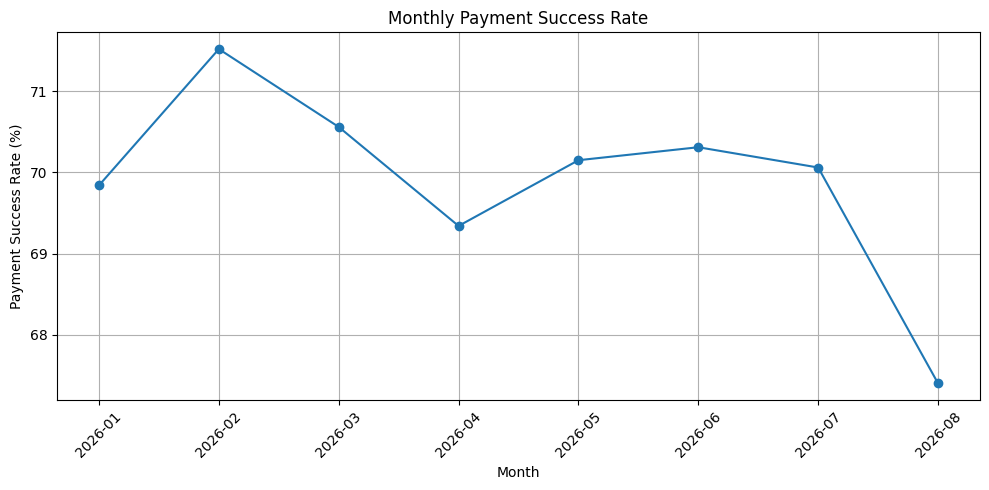

In [121]:
import matplotlib.pyplot as plt

monthly_recovery["month"] = monthly_recovery["month"].astype(str)

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_recovery["month"],
    monthly_recovery["recovery_rate"],
    marker="o"
)
plt.title("Monthly Payment Success Rate")
plt.xlabel("Month")
plt.ylabel("Payment Success Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [127]:
quality_summary = pd.DataFrame([
    {
        "dataset": "payments",
        "issue": "Exact duplicate rows",
        "count": 486,
        "impact": "Potential overstatement of successful transactions and payment amounts"
    },
    {
        "dataset": "payments",
        "issue": "Missing payment references after payment_id deduplication",
        "count": int(payments_clean["payment_reference"].isna().sum()),
        "impact": "Transaction traceability is reduced"
    },
    {
        "dataset": "payments",
        "issue": "Payment records with unmatched borrower IDs",
        "count": int((~payments_clean["borrower_exists"]).sum()),
        "impact": "Borrower attribution requires investigation"
    },
    {
        "dataset": "accounts",
        "issue": "Missing borrower IDs",
        "count": int(accounts["borrower_id"].isna().sum()),
        "impact": "Account-to-borrower linkage is incomplete"
    },
    {
        "dataset": "accounts",
        "issue": "Records with unmatched borrower IDs",
        "count": int((
            accounts["borrower_id"].notna() &
            ~accounts["borrower_id"].astype(str).isin(
                borrowers["borrower_id"].dropna().astype(str)
            )
        ).sum()),
        "impact": "Account-to-borrower relationships require reconciliation"
    }
])

display(quality_summary)


,dataset,issue,count,impact
0,payments,Exact duplicate rows,486,Potential overstatement of successful transact...
1,payments,Missing payment references after payment_id de...,368,Transaction traceability is reduced
2,payments,Payment records with unmatched borrower IDs,2043,Borrower attribution requires investigation
3,accounts,Missing borrower IDs,455,Account-to-borrower linkage is incomplete
4,accounts,Records with unmatched borrower IDs,2458,Account-to-borrower relationships require reco...


In [131]:


from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

monthly_recovery.to_csv(
    output_dir / "monthly_recovery_analysis.csv",
    index=False
)

quality_summary.to_csv(
    output_dir / "data_quality_report.csv",
    index=False
)

risk_monthly.to_csv(
    output_dir / "monthly_risk_analysis.csv",
    index=False
)

targeting_comparison.to_csv(
    output_dir / "targeting_comparison.csv",
    index=False
)

print("Analysis files saved successfully:")
for file in sorted(output_dir.glob("*.csv")):
    print(file)



Analysis files saved successfully:
outputs\data_quality_report.csv
outputs\monthly_recovery_analysis.csv
outputs\monthly_risk_analysis.csv
outputs\targeting_comparison.csv


In [133]:
from pathlib import Path

project_dir = Path.cwd()

for item in sorted(project_dir.iterdir()):
    print(item.name, "— folder" if item.is_dir() else "— file")
    

.ipynb_checkpoints — folder
01_dataset_inspection.ipynb — file
data — folder
outputs — folder


In [135]:
from pathlib import Path

project_dir = Path.cwd()
submission_dir = project_dir / "submission"

submission_dir.mkdir(exist_ok=True)

print("Submission folder location:")
print(submission_dir)

Submission folder location:
C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission


In [137]:
from pathlib import Path

project_dir = Path.cwd()
pipeline_dir = project_dir / "golden_dataset"
pipeline_dir.mkdir(exist_ok=True)

pipeline_file = pipeline_dir / "build_golden_dataset.py"

print("Pipeline folder:", pipeline_dir)
print("Pipeline file location:", pipeline_file)

Pipeline folder: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\golden_dataset
Pipeline file location: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\golden_dataset\build_golden_dataset.py


In [141]:

from pathlib import Path

project_dir = Path.cwd()
pipeline_dir = project_dir / "golden_dataset"
pipeline_dir.mkdir(exist_ok=True)

pipeline_code = '''
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(__file__).resolve().parent.parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
OUTPUT_DIR = PROJECT_DIR / "golden_dataset" / "data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

quality_records = []
key_columns = {
    "accounts": "account_id",
    "borrowers": "borrower_id",
    "agents": "agent_id",
    "agent_sessions": "session_id",
    "calls": "call_id",
    "call_attempts": "attempt_id",
    "call_dispositions": "disposition_id",
    "payments": "payment_id",
    "promises_to_pay": "ptp_id",
    "field_visits": "visit_id",
    "sms_events": "sms_event_id",
    "whatsapp_events": "whatsapp_event_id",
    "complaints": "complaint_id",
    "account_status_history": "history_id",
    "daily_targeting": "target_id"
}

for file_path in sorted(RAW_DIR.glob("*.csv")):
    if file_path.name == "data_dictionary.csv":
        continue

    dataset_name = file_path.stem
    df = pd.read_csv(file_path, low_memory=False)
    original_rows = len(df)
    exact_duplicates = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()
    key = key_columns.get(dataset_name)

    quality_records.append({
        "dataset": dataset_name,
        "raw_rows": original_rows,
        "exact_duplicate_rows_removed": exact_duplicates,
        "rows_after_exact_deduplication": len(df),
        "candidate_key": key,
        "missing_candidate_key": int(df[key].isna().sum()) if key and key in df.columns else None,
        "duplicate_candidate_key_rows": int(df[key].duplicated(keep=False).sum()) if key and key in df.columns else None
    })

    df.to_csv(OUTPUT_DIR / f"{dataset_name}_clean.csv", index=False)

quality_report = pd.DataFrame(quality_records)
quality_report.to_csv(OUTPUT_DIR / "pipeline_quality_report.csv", index=False)

print("Pipeline completed.")
print("Cleaned datasets:", len(quality_records))
print("Output directory:", OUTPUT_DIR)
print(quality_report.to_string(index=False))
'''

pipeline_file = pipeline_dir / "build_golden_dataset.py"
pipeline_file.write_text(pipeline_code, encoding="utf-8")

print("Pipeline script created:")
print(pipeline_file)



Pipeline script created:
C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\golden_dataset\build_golden_dataset.py


In [146]:
from pathlib import Path

pipeline_output = Path.cwd() / "golden_dataset" / "data"

for file in sorted(pipeline_output.glob("*")):
    print(file.name, f"— {file.stat().st_size:,} bytes")

In [148]:
from pathlib import Path

project_dir = Path.cwd()
pipeline_file = project_dir / "golden_dataset" / "build_golden_dataset.py"
pipeline_output = project_dir / "golden_dataset" / "data"

print("Project directory:", project_dir)
print("Pipeline script exists:", pipeline_file.exists())
print("Output folder exists:", pipeline_output.exists())

if pipeline_file.exists():
    print("Pipeline script size:", pipeline_file.stat().st_size, "bytes")

if pipeline_output.exists():
    print("Files created:", [file.name for file in pipeline_output.iterdir()])

Project directory: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment
Pipeline script exists: True
Output folder exists: False
Pipeline script size: 2026 bytes


In [151]:
import subprocess
import sys
from pathlib import Path

project_dir = Path.cwd()
pipeline_file = project_dir / "golden_dataset" / "build_golden_dataset.py"

result = subprocess.run(
    [sys.executable, str(pipeline_file)],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:")
print(result.stdout)
print("Errors:")
print(result.stderr)

Return code: 0
Output:
Pipeline completed.
Cleaned datasets: 17
Output directory: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\golden_dataset\data
               dataset  raw_rows  exact_duplicate_rows_removed  rows_after_exact_deduplication     candidate_key  missing_candidate_key  duplicate_candidate_key_rows
account_status_history     60000                             0                           60000        history_id                    0.0                           0.0
              accounts     30000                             0                           30000        account_id                    0.0                           0.0
        agent_sessions     15000                             0                           15000        session_id                    0.0                           0.0
                agents     30000                             0                           30000          agent_id                    0.0                       30000.0
          

In [153]:
from pathlib import Path
import shutil

project_dir = Path.cwd()
submission_dir = project_dir / "submission"
submission_dir.mkdir(exist_ok=True)

source_file = project_dir / "golden_dataset" / "data" / "payments_clean.csv"
destination_file = submission_dir / "golden_payments.csv"

shutil.copy2(source_file, destination_file)

print("File copied:", destination_file.exists())
print("Location:", destination_file)

File copied: True
Location: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\golden_payments.csv


In [157]:
 id="q7bx20"
from pathlib import Path

project_dir = Path.cwd()
submission_dir = project_dir / "submission"
sql_dir = submission_dir / "sql"
sql_dir.mkdir(parents=True, exist_ok=True)

sql_code = """
SELECT
    DATE_TRUNC('month', CAST(event_at AS TIMESTAMP)) AS month,
    COUNT(*) AS total_transactions,
    SUM(CASE WHEN payment_status = 'SUCCESS' THEN 1 ELSE 0 END) AS successful_transactions,
    SUM(CASE WHEN payment_status = 'SUCCESS' THEN amount ELSE 0 END) AS recovered_amount,
    ROUND(
        100.0 * SUM(CASE WHEN payment_status = 'SUCCESS' THEN 1 ELSE 0 END)
        / NULLIF(COUNT(*), 0),
        2
    ) AS payment_success_rate_pct
FROM payments
GROUP BY DATE_TRUNC('month', CAST(event_at AS TIMESTAMP))
ORDER BY month;

SELECT
    payment_id,
    COUNT(*) AS row_count
FROM payments
GROUP BY payment_id
HAVING COUNT(*) > 1
ORDER BY row_count DESC;

SELECT
    COUNT(*) AS missing_payment_references
FROM payments
WHERE payment_reference IS NULL OR TRIM(payment_reference) = '';

SELECT
    p.borrower_id,
    COUNT(*) AS payment_records
FROM payments p
LEFT JOIN borrowers b
    ON p.borrower_id = b.borrower_id
WHERE b.borrower_id IS NULL
GROUP BY p.borrower_id
ORDER BY payment_records DESC;
"""

sql_file = sql_dir / "collections_analysis.sql"
sql_file.write_text(sql_code.strip() + "\\n", encoding="utf-8")

print("SQL file created:", sql_file)



SQL file created: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\sql\collections_analysis.sql


In [159]:
from pathlib import Path

project_dir = Path.cwd()
reports_dir = project_dir / "submission" / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

print("Reports folder ready:", reports_dir)

Reports folder ready: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\reports


In [161]:
from pathlib import Path

project_dir = Path.cwd()
reports_dir = project_dir / "submission" / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

print("Reports folder ready:", reports_dir)

Reports folder ready: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\reports


In [1]:
from pathlib import Path
from docx import Document
from docx.shared import Inches, Pt

project_dir = Path.cwd()
reports_dir = project_dir / "submission" / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

doc = Document()
section = doc.sections[0]
section.top_margin = Inches(0.65)
section.bottom_margin = Inches(0.65)
section.left_margin = Inches(0.75)
section.right_margin = Inches(0.75)

doc.styles["Normal"].font.name = "Arial"
doc.styles["Normal"].font.size = Pt(9)

doc.add_heading("Collections Performance: Executive Memo", 0)
doc.add_paragraph("Decision brief | Analysis period: January–August 8, 2026")

doc.add_heading("1. What happened?", level=1)
doc.add_paragraph(
    "The available payment data does not show a consistent month-on-month "
    "improvement in payment success rate. The rate was 69.84% in January, "
    "peaked at 71.52% in February, and was 70.06% in July. August's observed "
    "rate was 67.40%, but the dataset only runs through August 8 and should "
    "not be compared directly with complete months."
)

doc.add_heading("2. What may explain the pattern?", level=1)
doc.add_paragraph(
    "Initial portfolio and targeting analyses show differences across risk "
    "segments and communication channels, but they do not establish causation. "
    "Targeting contact rates were broadly similar across channels before July "
    "and from July onward. More analysis is needed to test portfolio mix, "
    "campaign attribution, agent performance, and targeting effects."
)

doc.add_heading("3. Data quality and confidence", level=1)
doc.add_paragraph(
    "The raw payment table contains 25,500 rows. Exact-row deduplication "
    "removed 486 excess rows, leaving 25,014 rows. A separate exploratory "
    "step retained one row per payment_id, resulting in 25,000 records; this "
    "rule requires source-of-truth validation before adoption. After that step, "
    "368 payment references were missing and 2,043 payment records had borrower "
    "IDs that did not match the borrower table. The accounts table also had "
    "455 missing borrower IDs and 2,458 non-missing borrower IDs without a "
    "match. These issues reduce confidence in attribution and linkage."
)
doc.add_paragraph(
    "Confidence is moderate for the descriptive payment-success calculations "
    "and low for conclusions about actual debt recovery, causal drivers, or "
    "the reported 11% claim. Payment success rate is not equivalent to recovery "
    "rate, which requires a validated recovery numerator and portfolio denominator."
)

doc.add_heading("4. Recommended action and investment", level=1)
doc.add_paragraph(
    "Do not commit the full ₹10 Cr to a channel or operational intervention "
    "based on the current evidence. Better borrower targeting is a reasonable "
    "candidate to test, but its incremental recovery and ROI have not been "
    "established. Run a controlled pilot that randomly assigns eligible accounts "
    "to current targeting and improved targeting, stratified by risk, DPD, loan "
    "type, and geography. Measure incremental cash recovered per eligible account, "
    "net of reversals and intervention costs, over a prespecified follow-up window."
)

doc.add_heading("5. Financial impact and next steps", level=1)
doc.add_paragraph(
    "A defensible estimate of incremental recovery, ROI, and break-even cannot "
    "yet be calculated because the current analysis does not establish a causal "
    "lift or validated cost per incremental rupee recovered. Before investment, "
    "reconcile payment IDs and references, validate timestamps and reversal "
    "handling, define the recovery denominator, and quantify pilot costs. Scale "
    "only if the pilot's incremental recovery and downside case meet a pre-agreed "
    "investment hurdle."
)

doc.add_paragraph(
    "Conclusion: The available evidence does not substantiate the reported "
    "11% month-on-month improvement in actual recovery. It also does not prove "
    "that the claim is false. Validate the recovery metric and run a controlled "
    "experiment before committing the full investment."
)

memo_path = reports_dir / "executive_memo.docx"
doc.save(memo_path)

print("Executive memo created:", memo_path)

Executive memo created: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\reports\executive_memo.docx


In [165]:
%pip install python-docx

  Using cached python_docx-1.2.0-py3-none-any.whl.metadata (2.0 kB)
Using cached python_docx-1.2.0-py3-none-any.whl (252 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path

project_dir = Path.cwd()
submission_dir = project_dir / "submission"
submission_dir.mkdir(exist_ok=True)

diagram = """
flowchart TD
    A["Raw CSV Sources"] --> B["Staging Layer"]
    B --> C["Data Quality Checks"]
    C --> D["Exact Deduplication"]
    D --> E["Cleaned Datasets"]
    E --> F["Golden Dataset Validation"]
    F --> G["Feature Layer"]
    G --> H["Metrics Layer"]
    H --> I["Executive Dashboard"]
    H --> J["Monthly Recovery Analysis"]

    C --> K["Data Quality Report"]
    K --> L["Rejected or Flagged Records"]
    L --> F

    M["Data Dictionary"] --> C
    N["Business Rules"] --> F
"""

diagram_file = submission_dir / "data_architecture.mmd"
diagram_file.write_text(diagram.strip() + "\n", encoding="utf-8")

print("Architecture diagram saved:", diagram_file)

Architecture diagram saved: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\data_architecture.mmd


In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path.cwd()
submission_dir = project_dir / "submission"
outputs_dir = project_dir / "outputs"
submission_dir.mkdir(exist_ok=True)

recovery = pd.read_csv(outputs_dir / "monthly_recovery_analysis.csv")
quality = pd.read_csv(outputs_dir / "data_quality_report.csv")
targeting = pd.read_csv(outputs_dir / "targeting_comparison.csv")

recovery["month"] = recovery["month"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(recovery["month"], recovery["recovery_rate"], marker="o")
axes[0].set_title("Monthly Payment Success Rate")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Success rate (%)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True)

if {"period", "contact_rate"}.issubset(targeting.columns):
    axes[1].bar(targeting["period"], targeting["contact_rate"])
    axes[1].set_title("Targeting Contact Rate")
    axes[1].set_ylabel("Contact rate (%)")
else:
    axes[1].text(0.5, 0.5, "Targeting comparison unavailable", ha="center", va="center")
    axes[1].set_axis_off()

fig.tight_layout()

chart_path = submission_dir / "dashboard_charts.png"
fig.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.close(fig)

latest = recovery.iloc[-1]
first = recovery.iloc[0]

html = f"""
<html>
<head>
<title>Collections Performance Dashboard</title>
<style>
body {{ font-family: Arial, sans-serif; margin: 30px; color: #243247; }}
h1 {{ margin-bottom: 5px; }}
.subtitle {{ color: #666; }}
.cards {{ display: flex; gap: 15px; margin: 25px 0; }}
.card {{ flex: 1; padding: 18px; background: #eef3f8; border-radius: 8px; }}
.value {{ font-size: 25px; font-weight: bold; margin-top: 8px; }}
img {{ max-width: 100%; height: auto; }}
.note {{ background: #fff5d8; padding: 15px; border-radius: 8px; }}
</style>
</head>
<body>
<h1>Collections Performance Dashboard</h1>
<div class="subtitle">January–August 2026 | August data is partial</div>
<div class="cards">
<div class="card">First observed monthly success rate<div class="value">{first['recovery_rate']:.2f}%</div></div>
<div class="card">Latest observed monthly success rate<div class="value">{latest['recovery_rate']:.2f}%</div></div>
<div class="card">Quality issues flagged<div class="value">{len(quality)}</div></div>
</div>
<h2>Performance and targeting</h2>
<img src="dashboard_charts.png">
<div class="note">
<strong>Interpretation:</strong> Payment success rate is not necessarily the same as debt recovery rate.
August covers only part of the month. The reported 11% month-on-month recovery improvement
cannot be confirmed from this metric alone. Validate payment attribution, reversals, and
the recovery denominator before making an investment decision.
</div>
</body>
</html>
"""

dashboard_path = submission_dir / "executive_dashboard.html"
dashboard_path.write_text(html, encoding="utf-8")

print("Dashboard created:", dashboard_path)
print("Chart saved:", chart_path)

Dashboard created: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\executive_dashboard.html
Chart saved: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\dashboard_charts.png


In [9]:
from pathlib import Path

submission_dir = Path.cwd() / "submission"

for item in sorted(submission_dir.rglob("*")):
    if item.is_file():
        print(f"{item.relative_to(submission_dir)} — {item.stat().st_size:,} bytes")

dashboard_charts.png — 65,536 bytes
data_architecture.mmd — 508 bytes
executive_dashboard.html — 1,410 bytes
golden_payments.csv — 2,648,185 bytes
reports\executive_memo.docx — 38,119 bytes
sql\collections_analysis.sql — 1,034 bytes


In [11]:
from pathlib import Path

project_dir = Path.cwd()
golden_dir = project_dir / "golden_dataset"

print("Golden Dataset folder exists:", golden_dir.exists())

for item in sorted(golden_dir.rglob("*")):
    if item.is_file():
        print(f"{item.relative_to(project_dir)} — {item.stat().st_size:,} bytes")

Golden Dataset folder exists: True
golden_dataset\build_golden_dataset.py — 2,026 bytes
golden_dataset\data\account_status_history_clean.csv — 6,100,641 bytes
golden_dataset\data\accounts_clean.csv — 2,928,372 bytes
golden_dataset\data\agent_sessions_clean.csv — 1,301,743 bytes
golden_dataset\data\agents_clean.csv — 2,902,228 bytes
golden_dataset\data\borrowers_clean.csv — 3,452,488 bytes
golden_dataset\data\call_attempts_clean.csv — 12,216,305 bytes
golden_dataset\data\call_dispositions_clean.csv — 3,454,750 bytes
golden_dataset\data\calls_clean.csv — 10,641,455 bytes
golden_dataset\data\campaigns_clean.csv — 10,079 bytes
golden_dataset\data\complaints_clean.csv — 886,794 bytes
golden_dataset\data\daily_targeting_clean.csv — 2,772,034 bytes
golden_dataset\data\field_visits_clean.csv — 3,556,937 bytes
golden_dataset\data\payments_clean.csv — 2,648,185 bytes
golden_dataset\data\pipeline_quality_report.csv — 924 bytes
golden_dataset\data\promises_to_pay_clean.csv — 1,918,173 bytes
golden

In [13]:
from pathlib import Path
import shutil

project_dir = Path.cwd()
submission_dir = project_dir / "submission"
golden_dir = project_dir / "golden_dataset"

destination = submission_dir / "golden_dataset"
destination.mkdir(parents=True, exist_ok=True)

source_script = golden_dir / "build_golden_dataset.py"
if source_script.exists():
    shutil.copy2(source_script, destination / "build_golden_dataset.py")

source_data = golden_dir / "data"
destination_data = destination / "data"
destination_data.mkdir(parents=True, exist_ok=True)

for file in source_data.glob("*.csv"):
    shutil.copy2(file, destination_data / file.name)

print("Golden Dataset copied to:", destination)
print("Files copied:", len(list(destination.rglob("*"))))

Golden Dataset copied to: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\golden_dataset
Files copied: 20


In [15]:
from pathlib import Path

project_dir = Path.cwd()
submission_dir = project_dir / "submission"

print("Project folder:", project_dir)
print("Submission folder exists:", submission_dir.exists())
print("Files:")

for item in sorted(submission_dir.rglob("*")):
    if item.is_file():
        print(item.name)

Project folder: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment
Submission folder exists: True
Files:
dashboard_charts.png
data_architecture.mmd
executive_dashboard.html
build_golden_dataset.py
account_status_history_clean.csv
accounts_clean.csv
agent_sessions_clean.csv
agents_clean.csv
borrowers_clean.csv
call_attempts_clean.csv
call_dispositions_clean.csv
calls_clean.csv
campaigns_clean.csv
complaints_clean.csv
daily_targeting_clean.csv
field_visits_clean.csv
payments_clean.csv
pipeline_quality_report.csv
promises_to_pay_clean.csv
sms_events_clean.csv
vendor_telephony_clean.csv
whatsapp_events_clean.csv
golden_payments.csv
executive_memo.docx
collections_analysis.sql


In [17]:
from pathlib import Path

project_dir = Path.cwd()
submission_dir = project_dir / "submission"

readme = """# Collections Data Analyst Assignment

## Project Overview
This project investigates collections payment performance, data quality, payment attribution, and targeting changes.

## Contents
- golden_dataset/: Cleaned datasets and the pipeline script.
- sql/collections_analysis.sql: SQL queries for payment performance and data-quality checks.
- reports/executive_memo.docx: Executive summary and recommendations.
- executive_dashboard.html: Dashboard summarising monthly performance and targeting.
- dashboard_charts.png: Dashboard visualisations.
- data_architecture.mmd: Proposed analytics architecture.
- golden_payments.csv: Cleaned payment dataset.

## Key Findings
- Payment success rate was 69.84% in January 2026.
- It peaked at 71.52% in February 2026.
- It was 70.06% in July 2026.
- The observed August rate was 67.40%, but August data is incomplete.
- Initial payment checks identified exact duplicate rows, missing payment references, and unmatched borrower IDs.

## Limitations
Payment success rate is not necessarily equivalent to debt recovery rate. The reported 11% month-on-month improvement cannot be confirmed without a validated recovery definition, denominator, and payment attribution process. Exact duplicate removal does not resolve all duplicate IDs or conflicting records.

## Recommendation
Validate the recovery metric and payment attribution rules before making the full investment decision. Use a controlled pilot to measure incremental recovery and costs before scaling an intervention.

## Reproducibility
The original notebook is 01_dataset_inspection.ipynb. The Golden Dataset pipeline is build_golden_dataset.py. Review the source paths and dependencies before rerunning the pipeline.
"""

readme_path = submission_dir / "README.md"
readme_path.write_text(readme, encoding="utf-8")

print("README created:", readme_path)

README created: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission\README.md


In [19]:
from pathlib import Path
import shutil

project_dir = Path.cwd()
submission_dir = project_dir / "submission"
notebook_path = project_dir / "01_dataset_inspection.ipynb"

if notebook_path.exists():
    shutil.copy2(notebook_path, submission_dir / "01_dataset_inspection.ipynb")
    print("Notebook copied successfully.")
else:
    print("Notebook not found at:", notebook_path)

print("Submission folder:", submission_dir)

Notebook copied successfully.
Submission folder: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\submission


In [21]:
from pathlib import Path
import shutil

project_dir = Path.cwd()
submission_dir = project_dir / "submission"
zip_path = project_dir / "collections_assignment_submission.zip"

shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=submission_dir
)

print("ZIP created:", zip_path)
print("File size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")

ZIP created: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\collections_assignment_submission.zip
File size: 16.24 MB


In [23]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        print(name)

golden_dataset/
reports/
sql/
01_dataset_inspection.ipynb
dashboard_charts.png
data_architecture.mmd
executive_dashboard.html
golden_payments.csv
README.md
golden_dataset/data/
golden_dataset/build_golden_dataset.py
golden_dataset/data/accounts_clean.csv
golden_dataset/data/account_status_history_clean.csv
golden_dataset/data/agents_clean.csv
golden_dataset/data/agent_sessions_clean.csv
golden_dataset/data/borrowers_clean.csv
golden_dataset/data/calls_clean.csv
golden_dataset/data/call_attempts_clean.csv
golden_dataset/data/call_dispositions_clean.csv
golden_dataset/data/campaigns_clean.csv
golden_dataset/data/complaints_clean.csv
golden_dataset/data/daily_targeting_clean.csv
golden_dataset/data/field_visits_clean.csv
golden_dataset/data/payments_clean.csv
golden_dataset/data/pipeline_quality_report.csv
golden_dataset/data/promises_to_pay_clean.csv
golden_dataset/data/sms_events_clean.csv
golden_dataset/data/vendor_telephony_clean.csv
golden_dataset/data/whatsapp_events_clean.csv
repor

In [25]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()
    required_files = [
        "data_quality_report.csv",
        "monthly_recovery_analysis.csv",
        "monthly_risk_analysis.csv",
        "targeting_comparison.csv"
    ]

    for file in required_files:
        matches = [name for name in files if name.endswith(file)]
        print(file, "FOUND" if matches else "MISSING", matches)

data_quality_report.csv MISSING []
monthly_recovery_analysis.csv MISSING []
monthly_risk_analysis.csv MISSING []
targeting_comparison.csv MISSING []


In [27]:
from pathlib import Path
import shutil

project_dir = Path.cwd()
outputs_dir = project_dir / "outputs"
submission_dir = project_dir / "submission"

required_files = [
    "data_quality_report.csv",
    "monthly_recovery_analysis.csv",
    "monthly_risk_analysis.csv",
    "targeting_comparison.csv"
]

for filename in required_files:
    source = outputs_dir / filename
    destination = submission_dir / filename

    if source.exists():
        shutil.copy2(source, destination)
        print("Copied:", filename)
    else:
        print("NOT FOUND:", source)

Copied: data_quality_report.csv
Copied: monthly_recovery_analysis.csv
Copied: monthly_risk_analysis.csv
Copied: targeting_comparison.csv


In [29]:
import shutil
from pathlib import Path

project_dir = Path.cwd()
submission_dir = project_dir / "submission"
zip_path = project_dir / "collections_assignment_submission.zip"

shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=submission_dir
)

print("Updated ZIP:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")

Updated ZIP: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\collections_assignment_submission.zip
ZIP size: 16.24 MB


In [31]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    required_files = [
        "data_quality_report.csv",
        "monthly_recovery_analysis.csv",
        "monthly_risk_analysis.csv",
        "targeting_comparison.csv"
    ]

    for filename in required_files:
        matches = [name for name in files if name.endswith(filename)]
        print(filename, "FOUND" if matches else "MISSING")

data_quality_report.csv FOUND
monthly_recovery_analysis.csv FOUND
monthly_risk_analysis.csv FOUND
targeting_comparison.csv FOUND


In [33]:
from pathlib import Path
import subprocess
import sys

project_dir = Path.cwd()
pipeline_file = project_dir / "golden_dataset" / "build_golden_dataset.py"

result = subprocess.run(
    [sys.executable, str(pipeline_file)],
    capture_output=True,
    text=True,
    timeout=300
)

print("Return code:", result.returncode)
print("Output:")
print(result.stdout)
print("Errors:")
print(result.stderr)

Return code: 0
Output:
Pipeline completed.
Cleaned datasets: 17
Output directory: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\golden_dataset\data
               dataset  raw_rows  exact_duplicate_rows_removed  rows_after_exact_deduplication     candidate_key  missing_candidate_key  duplicate_candidate_key_rows
account_status_history     60000                             0                           60000        history_id                    0.0                           0.0
              accounts     30000                             0                           30000        account_id                    0.0                           0.0
        agent_sessions     15000                             0                           15000        session_id                    0.0                           0.0
                agents     30000                             0                           30000          agent_id                    0.0                       30000.0
          

In [35]:
import pandas as pd
from pathlib import Path

raw_dir = Path.cwd() / "data" / "raw"
golden_dir = Path.cwd() / "golden_dataset" / "data"

raw_borrowers = pd.read_csv(raw_dir / "borrowers.csv")
clean_borrowers = pd.read_csv(golden_dir / "borrowers_clean.csv")
raw_payments = pd.read_csv(raw_dir / "payments.csv")
clean_payments = pd.read_csv(golden_dir / "payments_clean.csv")

results = pd.DataFrame([
    {
        "dataset": "Raw borrowers",
        "rows": len(raw_borrowers),
        "unique IDs": raw_borrowers["borrower_id"].nunique(),
        "duplicate ID rows": raw_borrowers["borrower_id"].duplicated().sum()
    },
    {
        "dataset": "Golden borrowers",
        "rows": len(clean_borrowers),
        "unique IDs": clean_borrowers["borrower_id"].nunique(),
        "duplicate ID rows": clean_borrowers["borrower_id"].duplicated().sum()
    },
    {
        "dataset": "Raw payments",
        "rows": len(raw_payments),
        "unique IDs": raw_payments["payment_id"].nunique(),
        "duplicate ID rows": raw_payments["payment_id"].duplicated().sum()
    },
    {
        "dataset": "Golden payments",
        "rows": len(clean_payments),
        "unique IDs": clean_payments["payment_id"].nunique(),
        "duplicate ID rows": clean_payments["payment_id"].duplicated().sum()
    }
])

display(results)

,dataset,rows,unique IDs,duplicate ID rows
0,Raw borrowers,30600,11015,19585
1,Golden borrowers,30000,11015,18985
2,Raw payments,25500,25000,500
3,Golden payments,25014,25000,14


In [37]:
borrower_counts = (
    clean_borrowers["borrower_id"]
    .value_counts()
    .reset_index()
)

borrower_counts.columns = ["borrower_id", "record_count"]

print("Borrower ID frequency:")
display(borrower_counts["record_count"].value_counts().sort_index())

print("Sample repeated borrower records:")
repeated_ids = borrower_counts.loc[
    borrower_counts["record_count"] > 1, "borrower_id"
].head(5)

display(
    clean_borrowers[
        clean_borrowers["borrower_id"].isin(repeated_ids)
    ].sort_values("borrower_id")
)

Borrower ID frequency:


record_count
1     2497
2     3089
3     2497
4     1606
5      796
6      364
7      102
8       50
9        9
10       4
11       1
Name: count, dtype: int64

Sample repeated borrower records:


,borrower_id,name,phone,email,city,created_at,updated_at,state
29815,BRW0001237,Rahul Verma,9.073984e+09,user2805@example.com,Gurugram,2026-01-22 05:05:20,2026-01-18 00:28:56,Haryana
1358,BRW0001237,Vikram Shah,9.792547e+09,user14653@example.com,Pune,2025-09-11 13:03:15,2026-03-19 01:42:04,Maharashtra
1449,BRW0001237,Pooja Nair,9.914982e+09,user6185@example.com,Hyderabad,2025-12-03 07:01:01,2025-08-28 22:07:55,Telangana
29001,BRW0001237,Ananya Rao,9.799197e+09,user2312@example.com,Pune,2026-02-27 05:21:09,2026-05-18 08:31:19,Maharashtra
27134,BRW0001237,Rohan Patel,9.676859e+09,user6172@example.com,Pune,2025-09-16 00:50:30,2025-10-01 04:19:27,Maharashtra
23614,BRW0001237,Sneha Das,9.134612e+09,user8863@example.com,Jaipur,2025-09-02 22:14:26,2025-09-02 03:22:50,Rajasthan
26796,BRW0001237,Priya Mehta,9.918829e+09,user880@example.com,Gurugram,2025-08-07 17:03:09,2025-01-29 10:43:02,Haryana
24531,BRW0001237,Amit Kumar,9.692209e+09,user9638@example.com,Bengaluru,2026-02-01 04:15:48,2025-02-11 14:21:33,Karnataka
12260,BRW0001237,Neha Singh,9.377185e+09,user4691@example.com,Kolkata,2026-01-16 03:53:36,2025-05-14 19:35:08,West Bengal
25605,BRW0001237,Amit Kumar,9.520014e+09,user12236@example.com,Mumbai,2026-05-29 15:21:24,2026-07-24 03:16:15,Maharashtra


In [39]:
borrower_conflicts = clean_borrowers.groupby("borrower_id").agg(
    record_count=("borrower_id", "size"),
    unique_names=("name", "nunique"),
    unique_phones=("phone", "nunique"),
    unique_emails=("email", "nunique"),
    unique_cities=("city", "nunique"),
    unique_states=("state", "nunique")
).reset_index()

borrower_conflicts["identity_conflict"] = (
    (borrower_conflicts["unique_names"] > 1) |
    (borrower_conflicts["unique_phones"] > 1) |
    (borrower_conflicts["unique_emails"] > 1)
)

print("Total borrower IDs:", len(borrower_conflicts))
print("IDs with conflicting identity details:", borrower_conflicts["identity_conflict"].sum())
print("IDs with multiple names:", (borrower_conflicts["unique_names"] > 1).sum())
print("IDs with multiple phone numbers:", (borrower_conflicts["unique_phones"] > 1).sum())
print("IDs with multiple emails:", (borrower_conflicts["unique_emails"] > 1).sum())

display(
    borrower_conflicts[
        borrower_conflicts["identity_conflict"]
    ].sort_values("record_count", ascending=False).head(10)
)

Total borrower IDs: 11015
IDs with conflicting identity details: 8518
IDs with multiple names: 8185
IDs with multiple phone numbers: 8399
IDs with multiple emails: 8334


,borrower_id,record_count,unique_names,unique_phones,unique_emails,unique_cities,unique_states,identity_conflict
8150,BRW0008879,11,7,11,10,8,7,True
2327,BRW0002520,10,7,10,10,5,5,True
1153,BRW0001237,10,9,10,10,7,6,True
4966,BRW0005385,10,7,10,10,5,4,True
5812,BRW0006302,10,7,10,10,7,6,True
2217,BRW0002398,9,8,9,9,6,6,True
4624,BRW0005021,9,8,9,6,7,6,True
4452,BRW0004835,9,6,9,9,6,5,True
1863,BRW0002013,9,5,8,8,4,4,True
10144,BRW0011052,9,7,9,9,6,6,True


In [41]:
account_conflicts = accounts.groupby("account_id").agg(
    record_count=("account_id", "size"),
    unique_borrowers=("borrower_id", "nunique"),
    unique_statuses=("status", "nunique")
).reset_index()

print("Total accounts:", len(account_conflicts))
print("Accounts with repeated rows:", (account_conflicts["record_count"] > 1).sum())
print("Accounts linked to multiple borrowers:", (account_conflicts["unique_borrowers"] > 1).sum())
print("Accounts with multiple statuses:", (account_conflicts["unique_statuses"] > 1).sum())

display(account_conflicts[
    (account_conflicts["record_count"] > 1) |
    (account_conflicts["unique_borrowers"] > 1) |
    (account_conflicts["unique_statuses"] > 1)
].head(10))

NameError: name 'accounts' is not defined

In [43]:
from pathlib import Path
import pandas as pd

raw_dir = Path.cwd() / "data" / "raw"

accounts = pd.read_csv(raw_dir / "accounts.csv")
borrowers = pd.read_csv(raw_dir / "borrowers.csv")

print("Accounts:", accounts.shape)
print("Borrowers:", borrowers.shape)
print("Account columns:", accounts.columns.tolist())

Accounts: (30000, 11)
Borrowers: (30600, 8)
Account columns: ['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']


In [45]:
account_conflicts = accounts.groupby("account_id").agg(
    record_count=("account_id", "size"),
    unique_borrowers=("borrower_id", "nunique")
).reset_index()

print("Total accounts:", len(account_conflicts))
print("Accounts with repeated rows:", (account_conflicts["record_count"] > 1).sum())
print("Accounts linked to multiple borrowers:", (account_conflicts["unique_borrowers"] > 1).sum())

display(
    account_conflicts[
        (account_conflicts["record_count"] > 1) |
        (account_conflicts["unique_borrowers"] > 1)
    ].head(10)
)

Total accounts: 30000
Accounts with repeated rows: 0
Accounts linked to multiple borrowers: 0


,account_id,record_count,unique_borrowers


In [47]:
print("Payment columns:")
print(payments_clean.columns.tolist())

print("\nPayment date range:")
print(payments_clean["payment_date"].min())
print(payments_clean["payment_date"].max())

Payment columns:


NameError: name 'payments_clean' is not defined

In [49]:
from pathlib import Path
import pandas as pd

project_dir = Path.cwd()
golden_file = project_dir / "golden_dataset" / "data" / "payments_clean.csv"

payments_clean = pd.read_csv(golden_file)

print("Rows and columns:", payments_clean.shape)
print("Payment columns:")
print(payments_clean.columns.tolist())

Rows and columns: (25014, 9)
Payment columns:
['payment_id', 'account_id', 'borrower_id', 'event_at', 'payment_reference', 'amount', 'payment_status', 'payment_method', 'provider_id']


In [51]:
payments_clean["event_at"] = pd.to_datetime(
    payments_clean["event_at"],
    errors="coerce",
    utc=True
)

print("Date range:")
print("Earliest:", payments_clean["event_at"].min())
print("Latest:", payments_clean["event_at"].max())

print("\nPayment statuses:")
display(
    payments_clean.groupby("payment_status").agg(
        records=("payment_id", "size"),
        unique_payments=("payment_id", "nunique"),
        total_amount=("amount", "sum")
    ).reset_index()
)

print("\nMissing timestamps:", payments_clean["event_at"].isna().sum())

Date range:
Earliest: 2026-01-01 00:14:40+00:00
Latest: 2026-08-08 23:50:23+00:00

Payment statuses:


,payment_status,records,unique_payments,total_amount
0,FAILED,3678,3677,2.784453e+08
1,PENDING,2536,2535,1.903653e+08
2,REVERSED,1255,1254,9.467448e+07
3,SUCCESS,17545,17534,1.316474e+09



Missing timestamps: 0


In [53]:
payments_clean["amount"] = pd.to_numeric(
    payments_clean["amount"], errors="coerce"
)

payments_clean["month"] = (
    payments_clean["event_at"].dt.to_period("M").astype(str)
)

monthly_status = payments_clean.pivot_table(
    index="month",
    columns="payment_status",
    values="payment_id",
    aggfunc="count",
    fill_value=0
).reset_index()

monthly_amounts = payments_clean.assign(
    successful_amount=payments_clean["amount"].where(
        payments_clean["payment_status"].eq("SUCCESS"), 0
    ),
    reversed_amount=payments_clean["amount"].where(
        payments_clean["payment_status"].eq("REVERSED"), 0
    )
).groupby("month", as_index=False).agg(
    successful_amount=("successful_amount", "sum"),
    reversed_amount=("reversed_amount", "sum"),
    total_records=("payment_id", "count")
)

monthly_status = monthly_status.merge(
    monthly_amounts,
    on="month",
    how="left"
)

display(monthly_status)

C:\Users\keert\AppData\Local\Temp\ipykernel_26696\575808168.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  payments_clean["event_at"].dt.to_period("M").astype(str)


,month,FAILED,PENDING,REVERSED,SUCCESS,successful_amount,reversed_amount,total_records
0,2026-01,515,375,174,2464,1.872291e+08,11631225.06,3528
1,2026-02,451,312,140,2270,1.702796e+08,11477682.67,3173
2,2026-03,533,334,187,2527,1.891903e+08,14372369.75,3581
3,2026-04,511,376,177,2407,1.752289e+08,13327361.41,3471
4,2026-05,539,344,160,2450,1.843355e+08,12690920.44,3493
5,2026-06,474,352,173,2369,1.758534e+08,12949477.35,3368
6,2026-07,516,329,199,2442,1.872478e+08,15266393.46,3486
7,2026-08,139,114,45,616,4.710970e+07,2959050.67,914


In [55]:
monthly_status["successful_amount_change_pct"] = (
    monthly_status["successful_amount"].pct_change() * 100
).round(2)

monthly_status["successful_transactions_change_pct"] = (
    monthly_status["SUCCESS"].pct_change() * 100
).round(2)

monthly_status["reversed_amount_change_pct"] = (
    monthly_status["reversed_amount"].pct_change() * 100
).round(2)

display(
    monthly_status[
        [
            "month",
            "successful_amount",
            "successful_amount_change_pct",
            "SUCCESS",
            "successful_transactions_change_pct",
            "reversed_amount_change_pct"
        ]
    ]
)

,month,successful_amount,successful_amount_change_pct,SUCCESS,successful_transactions_change_pct,reversed_amount_change_pct
0,2026-01,1.872291e+08,NaN,2464,NaN,NaN
1,2026-02,1.702796e+08,-9.05,2270,-7.87,-1.32
2,2026-03,1.891903e+08,11.11,2527,11.32,25.22
3,2026-04,1.752289e+08,-7.38,2407,-4.75,-7.27
4,2026-05,1.843355e+08,5.20,2450,1.79,-4.78
5,2026-06,1.758534e+08,-4.60,2369,-3.31,2.04
6,2026-07,1.872478e+08,6.48,2442,3.08,17.89
7,2026-08,4.710970e+07,-74.84,616,-74.77,-80.62


In [57]:
duplicate_payment_ids = payments_clean[
    payments_clean.duplicated("payment_id", keep=False)
].sort_values("payment_id")

print("Rows involved in repeated payment IDs:", len(duplicate_payment_ids))
print("Distinct repeated payment IDs:", duplicate_payment_ids["payment_id"].nunique())

display(duplicate_payment_ids)


Rows involved in repeated payment IDs: 28
Distinct repeated payment IDs: 14


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id,month
1389,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59+00:00,TXN0000046535,85205.16,SUCCESS,CASH,VND0000015,2026-05
25000,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59+00:00,NaN,85205.16,SUCCESS,CASH,VND0000015,2026-05
2097,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16+00:00,TXN0000001302,5570.92,SUCCESS,NETBANKING,VND0000001,2026-07
25001,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16+00:00,NaN,5570.92,SUCCESS,NETBANKING,VND0000001,2026-07
2302,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47+00:00,TXN0000067311,59429.86,SUCCESS,CARD,VND0000011,2026-06
25002,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47+00:00,NaN,59429.86,SUCCESS,CARD,VND0000011,2026-06
25013,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03+00:00,TXN0000041890,107235.47,SUCCESS,NACH,VND0000002,2026-06
5190,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03+00:00,NaN,107235.47,SUCCESS,NACH,VND0000002,2026-06
25011,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42+00:00,TXN0000013106,119714.20,SUCCESS,NETBANKING,VND0000014,2026-03
7581,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42+00:00,NaN,119714.20,SUCCESS,NETBANKING,VND0000014,2026-03


In [59]:
comparison_columns = [
    "account_id",
    "borrower_id",
    "event_at",
    "amount",
    "payment_status",
    "payment_method",
    "provider_id"
]

duplicate_audit = (
    payments_clean[
        payments_clean["payment_id"].isin(duplicate_payment_ids["payment_id"])
    ]
    .groupby("payment_id")
    .agg(
        row_count=("payment_id", "size"),
        distinct_accounts=("account_id", "nunique"),
        distinct_borrowers=("borrower_id", "nunique"),
        distinct_timestamps=("event_at", "nunique"),
        distinct_amounts=("amount", "nunique"),
        distinct_statuses=("payment_status", "nunique"),
        distinct_methods=("payment_method", "nunique"),
        distinct_providers=("provider_id", "nunique"),
        missing_references=("payment_reference", lambda x: x.isna().sum()),
        distinct_references=("payment_reference", "nunique")
    )
    .reset_index()
)

display(duplicate_audit)

,payment_id,row_count,distinct_accounts,distinct_borrowers,distinct_timestamps,distinct_amounts,distinct_statuses,distinct_methods,distinct_providers,missing_references,distinct_references
0,PAYMENT0001390,2,1,1,1,1,1,1,1,1,1
1,PAYMENT0002098,2,1,1,1,1,1,1,1,1,1
2,PAYMENT0002303,2,1,1,1,1,1,1,1,1,1
3,PAYMENT0005191,2,1,1,1,1,1,1,1,1,1
4,PAYMENT0007582,2,1,1,1,1,1,1,1,1,1
5,PAYMENT0007751,2,1,1,1,1,1,1,1,1,1
6,PAYMENT0008752,2,1,1,1,1,1,1,1,1,1
7,PAYMENT0010558,2,1,1,1,1,1,1,1,1,1
8,PAYMENT0016862,2,1,1,1,1,1,1,1,1,1
9,PAYMENT0018134,2,1,1,1,1,1,1,1,1,1


In [61]:
payments_analysis = payments_clean.copy()

payments_analysis["reference_missing"] = payments_analysis["payment_reference"].isna()

payments_analysis = (
    payments_analysis
    .sort_values(
        ["payment_id", "reference_missing"],
        ascending=[True, True]
    )
    .drop_duplicates(subset=["payment_id"], keep="first")
    .drop(columns=["reference_missing"])
    .sort_values("event_at")
    .reset_index(drop=True)
)

print("Original cleaned rows:", len(payments_clean))
print("Analysis dataset rows:", len(payments_analysis))
print("Unique payment IDs:", payments_analysis["payment_id"].nunique())
print("Repeated payment IDs:", payments_analysis["payment_id"].duplicated().sum())
print("Missing payment references:", payments_analysis["payment_reference"].isna().sum())

Original cleaned rows: 25014
Analysis dataset rows: 25000
Unique payment IDs: 25000
Repeated payment IDs: 0
Missing payment references: 368


In [63]:
import pandas as pd

def payment_summary(df):
    return (
        df.groupby("payment_status")
        .agg(
            records=("payment_id", "size"),
            unique_payment_ids=("payment_id", "nunique"),
            amount=("amount", "sum")
        )
        .reset_index()
    )

summary_before = payment_summary(payments_clean)
summary_after = payment_summary(payments_analysis)

comparison = summary_before.merge(
    summary_after,
    on="payment_status",
    how="outer",
    suffixes=("_before", "_after")
)

comparison["records_removed"] = (
    comparison["records_before"] - comparison["records_after"]
)

comparison["amount_difference"] = (
    comparison["amount_before"] - comparison["amount_after"]
)

display(comparison.round(2))

,payment_status,records_before,unique_payment_ids_before,amount_before,records_after,unique_payment_ids_after,amount_after,records_removed,amount_difference
0,FAILED,3678,3677,2.784453e+08,3677,3677,2.784186e+08,1,26769.34
1,PENDING,2536,2535,1.903653e+08,2535,2535,1.902232e+08,1,142140.72
2,REVERSED,1255,1254,9.467448e+07,1254,1254,9.466657e+07,1,7914.90
3,SUCCESS,17545,17534,1.316474e+09,17534,17534,1.315584e+09,11,890499.50


In [65]:
status_summary = (
    payments_analysis.groupby("payment_status")
    .agg(
        payment_count=("payment_id", "nunique"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median")
    )
    .reset_index()
)

status_summary["total_amount"] = status_summary["total_amount"].round(2)
status_summary["average_amount"] = status_summary["average_amount"].round(2)
status_summary["median_amount"] = status_summary["median_amount"].round(2)

display(status_summary)

,payment_status,payment_count,total_amount,average_amount,median_amount
0,FAILED,3677,2.784186e+08,75718.95,76338.86
1,PENDING,2535,1.902232e+08,75038.73,74821.52
2,REVERSED,1254,9.466657e+07,75491.68,74382.57
3,SUCCESS,17534,1.315584e+09,75030.45,74976.38


In [67]:
from pathlib import Path
import pandas as pd

project_dir = Path.cwd()
accounts = pd.read_csv(project_dir / "data" / "raw" / "accounts.csv")

print("Shape:", accounts.shape)
print("\nColumns:")
print(accounts.columns.tolist())
print("\nData types:")
print(accounts.dtypes)
display(accounts.head(10))

Shape: (30000, 11)

Columns:
['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

Data types:
account_id             object
borrower_id            object
loan_type              object
principal_amount      float64
outstanding_amount    float64
dpd                     int64
risk_segment           object
status                 object
opened_at              object
timezone               object
schema_version         object
dtype: object


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,schema_version
0,ACC0000001,BRW0010742,CONSUMER,603443.40,678074.03,15,MEDIUM,CLOSED,2025-11-11 04:37:00,Asia/Dubai,v1
1,ACC0000002,BRW0009382,BNPL,277190.14,464893.44,5,LOW,ACTIVE,2025-11-13 15:59:44,UTC,v3
2,ACC0000003,BRW0003966,CREDIT_CARD,628658.43,22565.37,60,NPA,WRITEOFF,2025-09-12 04:59:20,Asia/Dubai,v2
3,ACC0000004,BRW0001993,PERSONAL,76435.07,508427.73,30,LOW,CLOSED,2025-05-25 19:29:38,UTC,v2
4,ACC0000005,BRW0009976,CONSUMER,646797.08,563858.01,180,LOW,WRITEOFF,2025-09-07 14:59:13,Asia/Dubai,v2
5,ACC0000006,NaN,BNPL,502458.93,326675.14,45,MEDIUM,CLOSED,2024-03-05 22:30:43,Asia/Kolkata,v1
6,ACC0000007,BRW0000727,BNPL,264110.65,438792.97,45,MEDIUM,CLOSED,2025-01-12 08:52:01,Asia/Kolkata,v1
7,ACC0000008,BRW0011565,PERSONAL,25601.77,413180.65,1,MEDIUM,WRITEOFF,2025-03-15 08:55:08,UTC,v2
8,ACC0000009,BRW0009929,AUTO,468473.94,546432.13,0,NPA,PAID,2024-07-03 01:36:33,UTC,v2
9,ACC0000010,BRW0010210,CREDIT_CARD,503912.27,480229.21,120,NPA,ACTIVE,2025-03-18 02:20:35,Asia/Dubai,v1


In [69]:
balance_columns = ["principal_amount", "outstanding_amount", "dpd"]

for column in balance_columns:
    accounts[column] = pd.to_numeric(accounts[column], errors="coerce")

print("Total accounts:", len(accounts))
print("Unique account IDs:", accounts["account_id"].nunique())
print("Missing principal amounts:", accounts["principal_amount"].isna().sum())
print("Missing outstanding amounts:", accounts["outstanding_amount"].isna().sum())
print("Missing DPD values:", accounts["dpd"].isna().sum())
print("Negative principal amounts:", (accounts["principal_amount"] < 0).sum())
print("Negative outstanding amounts:", (accounts["outstanding_amount"] < 0).sum())
print("Outstanding greater than principal:", (accounts["outstanding_amount"] > accounts["principal_amount"]).sum())
print("Zero outstanding balances:", (accounts["outstanding_amount"] == 0).sum())

display(
    accounts.groupby("status", dropna=False)
    .agg(
        account_count=("account_id", "nunique"),
        average_outstanding=("outstanding_amount", "mean"),
        total_outstanding=("outstanding_amount", "sum"),
        average_dpd=("dpd", "mean")
    )
    .round(2)
    .reset_index()
)

Total accounts: 30000
Unique account IDs: 30000
Missing principal amounts: 0
Missing outstanding amounts: 0
Missing DPD values: 0
Negative principal amounts: 0
Negative outstanding amounts: 0
Outstanding greater than principal: 13029
Zero outstanding balances: 0


,status,account_count,average_outstanding,total_outstanding,average_dpd
0,ACTIVE,7539,349833.78,2.637397e+09,56.26
1,CLOSED,7496,351673.33,2.636143e+09,55.91
2,PAID,7486,349657.97,2.617540e+09,57.26
3,WRITEOFF,7479,347366.72,2.597956e+09,56.59


In [71]:
accounts["outstanding_exceeds_principal"] = (
    accounts["outstanding_amount"] > accounts["principal_amount"]
)

accounts["outstanding_to_principal_ratio"] = (
    accounts["outstanding_amount"] / accounts["principal_amount"]
)

accounts["zero_outstanding"] = accounts["outstanding_amount"].eq(0)

status_balance_audit = (
    accounts.groupby("status", dropna=False)
    .agg(
        account_count=("account_id", "size"),
        positive_outstanding=("outstanding_amount", lambda x: (x > 0).sum()),
        zero_outstanding=("zero_outstanding", "sum"),
        exceeds_principal=("outstanding_exceeds_principal", "sum"),
        median_balance_ratio=("outstanding_to_principal_ratio", "median"),
        maximum_balance_ratio=("outstanding_to_principal_ratio", "max")
    )
    .reset_index()
)

status_balance_audit["positive_outstanding_pct"] = (
    status_balance_audit["positive_outstanding"]
    / status_balance_audit["account_count"] * 100
).round(2)

status_balance_audit["exceeds_principal_pct"] = (
    status_balance_audit["exceeds_principal"]
    / status_balance_audit["account_count"] * 100
).round(2)

display(status_balance_audit.round(2))

,status,account_count,positive_outstanding,zero_outstanding,exceeds_principal,median_balance_ratio,maximum_balance_ratio,positive_outstanding_pct,exceeds_principal_pct
0,ACTIVE,7539,7539,0,3279,0.87,59.60,100.0,43.49
1,CLOSED,7496,7496,0,3231,0.87,65.27,100.0,43.10
2,PAID,7486,7486,0,3280,0.88,61.64,100.0,43.82
3,WRITEOFF,7479,7479,0,3239,0.87,69.45,100.0,43.31


In [73]:
print(accounts[[
    "account_id",
    "status",
    "principal_amount",
    "outstanding_amount",
    "outstanding_to_principal_ratio"
]].head(10).to_string(index=False))

print("\nBalance ratio summary:")
display(accounts["outstanding_to_principal_ratio"].describe().to_frame())

print("\nStatus values:")
print(accounts["status"].value_counts(dropna=False))

account_id   status  principal_amount  outstanding_amount  outstanding_to_principal_ratio
ACC0000001   CLOSED         603443.40           678074.03                        1.123675
ACC0000002   ACTIVE         277190.14           464893.44                        1.677164
ACC0000003 WRITEOFF         628658.43            22565.37                        0.035894
ACC0000004   CLOSED          76435.07           508427.73                        6.651760
ACC0000005 WRITEOFF         646797.08           563858.01                        0.871770
ACC0000006   CLOSED         502458.93           326675.14                        0.650153
ACC0000007   CLOSED         264110.65           438792.97                        1.661398
ACC0000008 WRITEOFF          25601.77           413180.65                       16.138753
ACC0000009     PAID         468473.94           546432.13                        1.166409
ACC0000010   ACTIVE         503912.27           480229.21                        0.953002

Balance r

,outstanding_to_principal_ratio
count,30000.000000
mean,1.970080
std,4.145621
min,0.001385
25%,0.429267
50%,0.871868
75%,1.705169
max,69.452854



Status values:
status
ACTIVE      7539
CLOSED      7496
PAID        7486
WRITEOFF    7479
Name: count, dtype: int64


In [75]:
extreme_balance_accounts = (
    accounts[
        [
            "account_id",
            "borrower_id",
            "loan_type",
            "principal_amount",
            "outstanding_amount",
            "dpd",
            "risk_segment",
            "status",
            "outstanding_to_principal_ratio"
        ]
    ]
    .sort_values("outstanding_to_principal_ratio", ascending=False)
    .head(20)
)

display(extreme_balance_accounts.round(3))

,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,outstanding_to_principal_ratio
12971,ACC0012972,BRW0010446,PERSONAL,10058.30,698577.64,60,HIGH,WRITEOFF,69.453
16803,ACC0016804,BRW0001520,AUTO,10330.65,676728.68,0,HIGH,WRITEOFF,65.507
11709,ACC0011710,BRW0002225,CONSUMER,10216.93,666825.30,120,NPA,CLOSED,65.267
19159,ACC0019160,BRW0011928,BNPL,10517.65,667852.81,120,LOW,CLOSED,63.498
14074,ACC0014075,BRW0004610,CONSUMER,10270.90,649848.34,15,HIGH,WRITEOFF,63.271
4920,ACC0004921,BRW0000587,PERSONAL,11134.40,686282.54,1,HIGH,PAID,61.636
9995,ACC0009996,BRW0009702,PERSONAL,11204.20,667788.22,45,LOW,ACTIVE,59.602
29659,ACC0029660,BRW0001106,BNPL,11802.47,684886.28,90,NPA,ACTIVE,58.029
9769,ACC0009770,BRW0007910,BNPL,11386.96,654390.43,15,NPA,WRITEOFF,57.468
13276,ACC0013277,BRW0002754,PERSONAL,11638.96,663975.82,0,HIGH,WRITEOFF,57.048


In [77]:
extreme_check = accounts.nlargest(
    20, "outstanding_to_principal_ratio"
)[
    [
        "account_id",
        "principal_amount",
        "outstanding_amount",
        "dpd",
        "risk_segment",
        "status",
        "outstanding_to_principal_ratio"
    ]
]

print("Highest balance ratio:", accounts["outstanding_to_principal_ratio"].max())
print("Accounts with ratio above 10:", (accounts["outstanding_to_principal_ratio"] > 10).sum())
print("Accounts with ratio above 20:", (accounts["outstanding_to_principal_ratio"] > 20).sum())

display(extreme_check.to_string(index=False))

Highest balance ratio: 69.45285386198464
Accounts with ratio above 10: 1013
Accounts with ratio above 20: 337


'account_id  principal_amount  outstanding_amount  dpd risk_segment   status  outstanding_to_principal_ratio\nACC0012972          10058.30           698577.64   60         HIGH WRITEOFF                       69.452854\nACC0016804          10330.65           676728.68    0         HIGH WRITEOFF                       65.506883\nACC0011710          10216.93           666825.30  120          NPA   CLOSED                       65.266699\nACC0019160          10517.65           667852.81  120          LOW   CLOSED                       63.498292\nACC0014075          10270.90           649848.34   15         HIGH WRITEOFF                       63.270827\nACC0004921          11134.40           686282.54    1         HIGH     PAID                       61.636239\nACC0009996          11204.20           667788.22   45          LOW   ACTIVE                       59.601598\nACC0029660          11802.47           684886.28   90          NPA   ACTIVE                       58.029063\nACC0009770        

In [79]:
accounts["ratio_above_10"] = accounts["outstanding_to_principal_ratio"] > 10
accounts["ratio_above_20"] = accounts["outstanding_to_principal_ratio"] > 20

loan_type_audit = (
    accounts.groupby("loan_type", dropna=False)
    .agg(
        account_count=("account_id", "size"),
        total_principal=("principal_amount", "sum"),
        total_outstanding=("outstanding_amount", "sum"),
        median_balance_ratio=("outstanding_to_principal_ratio", "median"),
        accounts_above_10=("ratio_above_10", "sum"),
        accounts_above_20=("ratio_above_20", "sum")
    )
    .reset_index()
)

loan_type_audit["pct_above_10"] = (
    loan_type_audit["accounts_above_10"]
    / loan_type_audit["account_count"] * 100
).round(2)

loan_type_audit["pct_above_20"] = (
    loan_type_audit["accounts_above_20"]
    / loan_type_audit["account_count"] * 100
).round(2)

display(loan_type_audit.round(2))

,loan_type,account_count,total_principal,total_outstanding,median_balance_ratio,accounts_above_10,accounts_above_20,pct_above_10,pct_above_20
0,AUTO,6079,2.440528e+09,2.135301e+09,0.88,210,60,3.45,0.99
1,BNPL,5928,2.389513e+09,2.058915e+09,0.87,190,67,3.21,1.13
2,CONSUMER,5930,2.387306e+09,2.073113e+09,0.87,208,79,3.51,1.33
3,CREDIT_CARD,6080,2.451801e+09,2.126677e+09,0.87,208,63,3.42,1.04
4,PERSONAL,5983,2.434517e+09,2.095030e+09,0.87,197,68,3.29,1.14


In [81]:
loan_type_check = accounts.groupby("loan_type").agg(
    account_count=("account_id", "count"),
    median_ratio=("outstanding_to_principal_ratio", "median"),
    accounts_above_10=("ratio_above_10", "sum"),
    accounts_above_20=("ratio_above_20", "sum")
).reset_index()

loan_type_check["pct_above_10"] = (
    loan_type_check["accounts_above_10"] / loan_type_check["account_count"] * 100
).round(2)

loan_type_check["pct_above_20"] = (
    loan_type_check["accounts_above_20"] / loan_type_check["account_count"] * 100
).round(2)

print(loan_type_check.to_string(index=False))

  loan_type  account_count  median_ratio  accounts_above_10  accounts_above_20  pct_above_10  pct_above_20
       AUTO           6079      0.877838                210                 60          3.45          0.99
       BNPL           5928      0.867161                190                 67          3.21          1.13
   CONSUMER           5930      0.872842                208                 79          3.51          1.33
CREDIT_CARD           6080      0.871627                208                 63          3.42          1.04
   PERSONAL           5983      0.869353                197                 68          3.29          1.14


In [83]:
from pathlib import Path
import pandas as pd

history = pd.read_csv(
    Path.cwd() / "data" / "raw" / "account_status_history.csv"
)

print("Shape:", history.shape)
print("Columns:", history.columns.tolist())
print("\nData types:")
print(history.dtypes)
display(history.head(10))

Shape: (60000, 8)
Columns: ['history_id', 'account_id', 'borrower_id', 'event_at', 'status', 'changed_by', 'source', 'recorded_at']

Data types:
history_id     object
account_id     object
borrower_id    object
event_at       object
status         object
changed_by     object
source         object
recorded_at    object
dtype: object


,history_id,account_id,borrower_id,event_at,status,changed_by,source,recorded_at
0,HISTORY0000001,ACC0004322,BRW0005490,2026-07-03 04:28:38,WRITEOFF,AGT0000039,CALL,2026-07-03 00:41:54
1,HISTORY0000002,ACC0024644,BRW0005343,2026-07-18 02:03:23,DELINQUENT,AGT0000059,CALL,2026-07-18 22:42:02
2,HISTORY0000003,ACC0020233,BRW0003150,2026-04-15 09:17:47,CLOSED,AGT0000080,PAYMENT,2026-04-15 19:40:51
3,HISTORY0000004,ACC0004384,BRW0008483,2026-01-16 10:52:04,WRITEOFF,SYSTEM,CORE,2026-01-16 23:05:28
4,HISTORY0000005,ACC0022967,BRW0009477,2026-05-22 04:13:04,PTP,AGT0000073,CORE,2026-05-22 07:08:28
5,HISTORY0000006,ACC0022426,BRW0004946,2026-05-16 21:50:29,PTP,AGT0000019,BATCH,2026-05-16 14:40:05
6,HISTORY0000007,ACC0008914,BRW0003477,2026-04-27 05:34:41,NPA,AGT0000079,PAYMENT,2026-04-27 01:29:33
7,HISTORY0000008,ACC0019988,BRW0009853,2026-07-24 13:38:50,ACTIVE,AGT0000043,CORE,2026-07-24 16:59:50
8,HISTORY0000009,ACC0011780,BRW0011971,2026-03-02 00:33:49,WRITEOFF,AGT0000016,PAYMENT,2026-03-01 17:33:30
9,HISTORY0000010,ACC0012911,BRW0008173,2026-02-19 04:15:43,WRITEOFF,AGT0000076,CALL,2026-02-19 20:20:37


In [85]:
history["event_at"] = pd.to_datetime(history["event_at"], errors="coerce")
history["recorded_at"] = pd.to_datetime(history["recorded_at"], errors="coerce")

history["recording_delay_hours"] = (
    history["recorded_at"] - history["event_at"]
).dt.total_seconds() / 3600

print("Total history records:", len(history))
print("Unique history IDs:", history["history_id"].nunique())
print("Duplicate history IDs:", history["history_id"].duplicated().sum())
print("Missing event timestamps:", history["event_at"].isna().sum())
print("Missing recorded timestamps:", history["recorded_at"].isna().sum())
print("Recorded before event:", (history["recording_delay_hours"] < 0).sum())
print("Recorded more than 24 hours after event:", (history["recording_delay_hours"] > 24).sum())

display(
    history["recording_delay_hours"].describe().to_frame()
)

display(
    history["status"].value_counts(dropna=False).rename_axis("status").reset_index(name="records")
)

Total history records: 60000
Unique history IDs: 60000
Duplicate history IDs: 0
Missing event timestamps: 0
Missing recorded timestamps: 0
Recorded before event: 30191
Recorded more than 24 hours after event: 0


,recording_delay_hours
count,60000.000000
mean,-0.096023
std,13.873956
min,-23.998611
25%,-12.128403
50%,-0.125972
75%,11.926111
max,23.999444


,status,records
0,PAID,8650
1,CLOSED,8614
2,DELINQUENT,8612
3,NPA,8612
4,WRITEOFF,8583
5,ACTIVE,8518
6,PTP,8411


In [87]:
history_sorted = history.sort_values(
    ["account_id", "event_at", "recorded_at"]
).copy()

history_sorted["previous_status"] = (
    history_sorted.groupby("account_id")["status"].shift(1)
)

history_sorted["previous_event_at"] = (
    history_sorted.groupby("account_id")["event_at"].shift(1)
)

history_sorted["hours_since_previous_event"] = (
    history_sorted["event_at"] - history_sorted["previous_event_at"]
).dt.total_seconds() / 3600

status_transitions = history_sorted[
    history_sorted["previous_status"].notna()
].copy()

print("History records:", len(history))
print("Accounts represented in history:", history["account_id"].nunique())
print("Status transitions available:", len(status_transitions))
print(
    "Events with unchanged status:",
    (status_transitions["status"] == status_transitions["previous_status"]).sum()
)
print(
    "Events with changed status:",
    (status_transitions["status"] != status_transitions["previous_status"]).sum()
)
print(
    "Negative gaps between event timestamps:",
    (status_transitions["hours_since_previous_event"] < 0).sum()
)

display(
    status_transitions[
        [
            "account_id",
            "previous_status",
            "status",
            "previous_event_at",
            "event_at",
            "hours_since_previous_event",
            "source"
        ]
    ].head(15)
)

History records: 60000
Accounts represented in history: 25999
Status transitions available: 34001
Events with unchanged status: 4937
Events with changed status: 29064
Negative gaps between event timestamps: 0


,account_id,previous_status,status,previous_event_at,event_at,hours_since_previous_event,source
31910,ACC0000002,PTP,DELINQUENT,2026-01-16 13:58:20,2026-05-04 14:33:12,2592.581111,CALL
57727,ACC0000002,DELINQUENT,DELINQUENT,2026-05-04 14:33:12,2026-05-15 13:04:13,262.516944,PAYMENT
24438,ACC0000003,PAID,CLOSED,2026-01-31 11:25:03,2026-04-15 18:19:36,1782.909167,CORE
16357,ACC0000003,CLOSED,WRITEOFF,2026-04-15 18:19:36,2026-05-20 01:02:35,822.716389,CORE
47639,ACC0000003,WRITEOFF,NPA,2026-05-20 01:02:35,2026-07-03 03:39:47,1058.620000,CALL
4798,ACC0000003,NPA,NPA,2026-07-03 03:39:47,2026-07-23 20:28:51,496.817778,BATCH
26660,ACC0000005,DELINQUENT,PTP,2026-01-24 18:59:39,2026-02-02 23:59:56,221.004722,PAYMENT
21322,ACC0000005,PTP,CLOSED,2026-02-02 23:59:56,2026-07-05 01:28:01,3649.468056,CORE
29778,ACC0000006,PAID,WRITEOFF,2026-02-12 05:45:10,2026-03-05 22:11:03,520.431389,PAYMENT
58496,ACC0000006,WRITEOFF,PAID,2026-03-05 22:11:03,2026-03-10 09:02:21,106.855000,BATCH


In [89]:
account_ids = set(accounts["account_id"].dropna())
history_account_ids = set(history["account_id"].dropna())

accounts_without_history = account_ids - history_account_ids
history_accounts_not_in_accounts = history_account_ids - account_ids

print("Accounts in account dataset:", len(account_ids))
print("Accounts represented in history:", len(history_account_ids))
print("Accounts without history:", len(accounts_without_history))
print("History accounts missing from account dataset:", len(history_accounts_not_in_accounts))

print(
    "History coverage percentage:",
    round(len(account_ids & history_account_ids) / len(account_ids) * 100, 2)
)

print("\nExamples of accounts without history:")
print(sorted(accounts_without_history)[:10])

print("\nExamples of history account IDs absent from accounts:")
print(sorted(history_accounts_not_in_accounts)[:10])

Accounts in account dataset: 30000
Accounts represented in history: 25999
Accounts without history: 4001
History accounts missing from account dataset: 0
History coverage percentage: 86.66

Examples of accounts without history:
['ACC0000021', 'ACC0000026', 'ACC0000031', 'ACC0000034', 'ACC0000038', 'ACC0000039', 'ACC0000055', 'ACC0000058', 'ACC0000061', 'ACC0000063']

Examples of history account IDs absent from accounts:
[]


In [91]:
account_ids = set(accounts["account_id"].dropna())
borrower_ids = set(clean_borrowers["borrower_id"].dropna())

payments_analysis["account_match"] = payments_analysis["account_id"].isin(account_ids)
payments_analysis["borrower_match"] = payments_analysis["borrower_id"].isin(borrower_ids)

print("Total unique payments:", len(payments_analysis))
print("Payments with missing account IDs:", payments_analysis["account_id"].isna().sum())
print("Payments with unmatched account IDs:", (~payments_analysis["account_match"]).sum())
print("Payments with missing borrower IDs:", payments_analysis["borrower_id"].isna().sum())
print("Payments with unmatched borrower IDs:", (~payments_analysis["borrower_match"]).sum())

print("\nAccount match results:")
print(payments_analysis["account_match"].value_counts())

print("\nBorrower match results:")
print(payments_analysis["borrower_match"].value_counts())

Total unique payments: 25000
Payments with missing account IDs: 0
Payments with unmatched account IDs: 0
Payments with missing borrower IDs: 0
Payments with unmatched borrower IDs: 2043

Account match results:
account_match
True    25000
Name: count, dtype: int64

Borrower match results:
borrower_match
True     22957
False     2043
Name: count, dtype: int64


In [93]:
account_borrower_map = accounts[
    ["account_id", "borrower_id"]
].rename(columns={"borrower_id": "account_borrower_id"})

payment_attribution = payments_analysis.merge(
    account_borrower_map,
    on="account_id",
    how="left",
    validate="many_to_one"
)

payment_attribution["borrower_matches_account"] = (
    payment_attribution["borrower_id"]
    == payment_attribution["account_borrower_id"]
)

print("Total payments:", len(payment_attribution))
print(
    "Payments whose borrower ID matches the account:",
    payment_attribution["borrower_matches_account"].sum()
)
print(
    "Payments whose borrower ID differs from the account:",
    (~payment_attribution["borrower_matches_account"]).sum()
)
print(
    "Accounts with missing borrower IDs:",
    payment_attribution["account_borrower_id"].isna().sum()
)

display(
    payment_attribution.loc[
        ~payment_attribution["borrower_matches_account"],
        [
            "payment_id",
            "account_id",
            "borrower_id",
            "account_borrower_id",
            "payment_status",
            "amount"
        ]
    ].head(15)
)

Total payments: 25000
Payments whose borrower ID matches the account: 1
Payments whose borrower ID differs from the account: 24999
Accounts with missing borrower IDs: 382


,payment_id,account_id,borrower_id,account_borrower_id,payment_status,amount
0,PAYMENT0008675,ACC0014142,BRW0001216,BRW0002123,SUCCESS,99867.36
1,PAYMENT0008644,ACC0003318,BRW0008843,BRW0010431,REVERSED,94128.59
2,PAYMENT0002693,ACC0014449,BRW0001005,BRW0001924,SUCCESS,101870.25
3,PAYMENT0004607,ACC0018164,BRW0008851,BRW0008813,FAILED,63882.71
4,PAYMENT0000307,ACC0026311,BRW0004699,BRW0002197,FAILED,68439.57
5,PAYMENT0024821,ACC0018361,BRW0008646,BRW0003273,SUCCESS,87906.80
6,PAYMENT0011191,ACC0004322,BRW0006412,BRW0006021,SUCCESS,94150.20
7,PAYMENT0008443,ACC0005569,BRW0009161,BRW0007231,SUCCESS,81954.29
8,PAYMENT0020533,ACC0002164,BRW0005627,BRW0010406,SUCCESS,74524.80
9,PAYMENT0018250,ACC0022477,BRW0004233,BRW0004045,PENDING,23224.76


In [95]:
attribution_summary = (
    payment_attribution.groupby("payment_status")
    .agg(
        total_payments=("payment_id", "size"),
        matching_borrowers=("borrower_matches_account", "sum"),
        distinct_accounts=("account_id", "nunique"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

attribution_summary["mismatched_borrowers"] = (
    attribution_summary["total_payments"]
    - attribution_summary["matching_borrowers"]
)

attribution_summary["mismatch_percentage"] = (
    attribution_summary["mismatched_borrowers"]
    / attribution_summary["total_payments"] * 100
).round(2)

display(attribution_summary.round(2))

,payment_status,total_payments,matching_borrowers,distinct_accounts,total_amount,mismatched_borrowers,mismatch_percentage
0,FAILED,3677,0,3443,2.784186e+08,3677,100.00
1,PENDING,2535,0,2430,1.902232e+08,2535,100.00
2,REVERSED,1254,0,1230,9.466657e+07,1254,100.00
3,SUCCESS,17534,1,13284,1.315584e+09,17533,99.99


In [97]:
borrower_identity_audit = (
    clean_borrowers.groupby("borrower_id", dropna=False)
    .agg(
        rows=("borrower_id", "size"),
        distinct_names=("name", "nunique"),
        distinct_phones=("phone", "nunique"),
        distinct_emails=("email", "nunique")
    )
    .reset_index()
)

print("Borrower records:", len(clean_borrowers))
print("Distinct borrower IDs:", clean_borrowers["borrower_id"].nunique())
print("IDs with multiple names:", (borrower_identity_audit["distinct_names"] > 1).sum())
print("IDs with multiple phone numbers:", (borrower_identity_audit["distinct_phones"] > 1).sum())
print("IDs with multiple email addresses:", (borrower_identity_audit["distinct_emails"] > 1).sum())

display(
    borrower_identity_audit.sort_values(
        ["distinct_names", "distinct_phones", "distinct_emails"],
        ascending=False
    ).head(10)
)


Borrower records: 30000
Distinct borrower IDs: 11015
IDs with multiple names: 8185
IDs with multiple phone numbers: 8399
IDs with multiple email addresses: 8334


,borrower_id,rows,distinct_names,distinct_phones,distinct_emails
1153,BRW0001237,10,9,10,10
2217,BRW0002398,9,8,9,9
4624,BRW0005021,9,8,9,6
8150,BRW0008879,11,7,11,10
2327,BRW0002520,10,7,10,10
4966,BRW0005385,10,7,10,10
5812,BRW0006302,10,7,10,10
10144,BRW0011052,9,7,9,9
3154,BRW0003415,8,7,8,8
3731,BRW0004044,8,7,8,8


In [99]:
payment_attribution["borrower_missing_from_master"] = (
    ~payment_attribution["borrower_id"].isin(
        clean_borrowers["borrower_id"].dropna()
    )
)

payment_attribution["account_borrower_missing"] = (
    payment_attribution["account_borrower_id"].isna()
)

payment_attribution["borrower_differs_from_account"] = (
    payment_attribution["borrower_id"]
    != payment_attribution["account_borrower_id"]
)

attribution_flags = pd.Series({
    "Payment borrower ID absent from borrower master": payment_attribution["borrower_missing_from_master"].sum(),
    "Account borrower ID missing": payment_attribution["account_borrower_missing"].sum(),
    "Payment borrower differs from account borrower": payment_attribution["borrower_differs_from_account"].sum(),
    "Payments with all three issues": (
        payment_attribution["borrower_missing_from_master"]
        & payment_attribution["account_borrower_missing"]
        & payment_attribution["borrower_differs_from_account"]
    ).sum()
})

display(attribution_flags.to_frame("count"))

,count
Payment borrower ID absent from borrower master,2043
Account borrower ID missing,382
Payment borrower differs from account borrower,24999
Payments with all three issues,44


In [101]:
accounts["borrower_in_master"] = accounts["borrower_id"].isin(
    clean_borrowers["borrower_id"].dropna()
)

account_mapping_audit = (
    accounts.groupby("status", dropna=False)
    .agg(
        total_accounts=("account_id", "nunique"),
        missing_borrower_ids=("borrower_id", lambda x: x.isna().sum()),
        borrower_ids_in_master=("borrower_in_master", "sum")
    )
    .reset_index()
)

account_mapping_audit["borrower_ids_not_in_master"] = (
    account_mapping_audit["total_accounts"]
    - account_mapping_audit["missing_borrower_ids"]
    - account_mapping_audit["borrower_ids_in_master"]
)

display(account_mapping_audit)

,status,total_accounts,missing_borrower_ids,borrower_ids_in_master,borrower_ids_not_in_master
0,ACTIVE,7539,119,6797,623
1,CLOSED,7496,109,6786,601
2,PAID,7486,122,6741,623
3,WRITEOFF,7479,105,6763,611


In [103]:
reference_audit = (
    payments_analysis.groupby("payment_reference", dropna=False)
    .agg(
        record_count=("payment_id", "size"),
        distinct_payment_ids=("payment_id", "nunique"),
        distinct_accounts=("account_id", "nunique"),
        distinct_amounts=("amount", "nunique"),
        distinct_statuses=("payment_status", "nunique"),
        distinct_providers=("provider_id", "nunique")
    )
    .reset_index()
)

reference_audit["is_missing_reference"] = reference_audit["payment_reference"].isna()

print("Total payment records:", len(payments_analysis))
print("Missing payment references:", payments_analysis["payment_reference"].isna().sum())
print(
    "Nonmissing references linked to multiple payment IDs:",
    (
        (~reference_audit["is_missing_reference"])
        & (reference_audit["distinct_payment_ids"] > 1)
    ).sum()
)
print(
    "Nonmissing references linked to multiple accounts:",
    (
        (~reference_audit["is_missing_reference"])
        & (reference_audit["distinct_accounts"] > 1)
    ).sum()
)

display(
    reference_audit.loc[
        (~reference_audit["is_missing_reference"])
        & (
            (reference_audit["distinct_payment_ids"] > 1)
            | (reference_audit["distinct_accounts"] > 1)
        )
    ].sort_values("record_count", ascending=False).head(10)
)

Total payment records: 25000
Missing payment references: 368
Nonmissing references linked to multiple payment IDs: 3407
Nonmissing references linked to multiple accounts: 3407


,payment_reference,record_count,distinct_payment_ids,distinct_accounts,distinct_amounts,distinct_statuses,distinct_providers,is_missing_reference
13081,TXN0000044312,5,5,5,5,2,3,False
1993,TXN0000006936,4,4,4,4,3,3,False
2728,TXN0000009490,4,4,4,4,1,4,False
6280,TXN0000021482,4,4,4,4,2,4,False
5835,TXN0000020022,4,4,4,4,3,4,False
3446,TXN0000011850,4,4,4,4,2,3,False
20690,TXN0000069582,4,4,4,4,3,4,False
5895,TXN0000020227,4,4,4,4,1,3,False
515,TXN0000001778,4,4,4,4,2,3,False
3869,TXN0000013291,4,4,4,4,2,4,False


In [105]:
provider_reference_audit = (
    payments_analysis.dropna(subset=["payment_reference"])
    .groupby(["provider_id", "payment_reference"])
    .agg(
        record_count=("payment_id", "size"),
        distinct_payment_ids=("payment_id", "nunique"),
        distinct_accounts=("account_id", "nunique"),
        distinct_amounts=("amount", "nunique"),
        distinct_statuses=("payment_status", "nunique")
    )
    .reset_index()
)

print("Provider-reference combinations:", len(provider_reference_audit))
print(
    "Provider-reference combinations with multiple payment IDs:",
    (provider_reference_audit["distinct_payment_ids"] > 1).sum()
)
print(
    "Provider-reference combinations with multiple accounts:",
    (provider_reference_audit["distinct_accounts"] > 1).sum()
)
print(
    "Provider-reference combinations with conflicting amounts:",
    (provider_reference_audit["distinct_amounts"] > 1).sum()
)

display(
    provider_reference_audit[
        provider_reference_audit["distinct_payment_ids"] > 1
    ].sort_values("record_count", ascending=False).head(15)
)

Provider-reference combinations: 24336
Provider-reference combinations with multiple payment IDs: 291
Provider-reference combinations with multiple accounts: 291
Provider-reference combinations with conflicting amounts: 291


,provider_id,payment_reference,record_count,distinct_payment_ids,distinct_accounts,distinct_amounts,distinct_statuses
10637,VND0000007,TXN0000037402,3,3,3,3,2
2684,VND0000002,TXN0000044622,3,3,3,3,2
17304,VND0000011,TXN0000044312,3,3,3,3,2
20794,VND0000013,TXN0000054308,3,3,3,3,2
20908,VND0000013,TXN0000059686,3,3,3,3,3
23,VND0000001,TXN0000000965,2,2,2,2,2
22499,VND0000014,TXN0000058414,2,2,2,2,1
22562,VND0000014,TXN0000061288,2,2,2,2,1
22616,VND0000014,TXN0000063591,2,2,2,2,1
22659,VND0000014,TXN0000065113,2,2,2,2,2


In [107]:
payments_analysis["month"] = (
    payments_analysis["event_at"]
    .dt.strftime("%Y-%m")
)

monthly_payment_metrics = (
    payments_analysis.assign(
        successful_amount=payments_analysis["amount"].where(
            payments_analysis["payment_status"].eq("SUCCESS"), 0
        ),
        reversed_amount=payments_analysis["amount"].where(
            payments_analysis["payment_status"].eq("REVERSED"), 0
        ),
        successful_count=payments_analysis["payment_status"].eq("SUCCESS").astype(int),
        reversed_count=payments_analysis["payment_status"].eq("REVERSED").astype(int)
    )
    .groupby("month", as_index=False)
    .agg(
        successful_amount=("successful_amount", "sum"),
        reversed_amount=("reversed_amount", "sum"),
        successful_count=("successful_count", "sum"),
        reversed_count=("reversed_count", "sum")
    )
)

monthly_payment_metrics["success_minus_reversed"] = (
    monthly_payment_metrics["successful_amount"]
    - monthly_payment_metrics["reversed_amount"]
)

monthly_payment_metrics["success_amount_change_pct"] = (
    monthly_payment_metrics["successful_amount"].pct_change() * 100
).round(2)

monthly_payment_metrics["success_minus_reversed_change_pct"] = (
    monthly_payment_metrics["success_minus_reversed"].pct_change() * 100
).round(2)

display(monthly_payment_metrics.round(2))

,month,successful_amount,reversed_amount,successful_count,reversed_count,success_minus_reversed,success_amount_change_pct,success_minus_reversed_change_pct
0,2026-01,1.872291e+08,11631225.06,2464,174,1.755979e+08,NaN,NaN
1,2026-02,1.701425e+08,11477682.67,2268,140,1.586648e+08,-9.13,-9.64
2,2026-03,1.889124e+08,14364454.85,2524,186,1.745479e+08,11.03,10.01
3,2026-04,1.751380e+08,13327361.41,2406,177,1.618107e+08,-7.29,-7.30
4,2026-05,1.842503e+08,12690920.44,2449,160,1.715594e+08,5.20,6.02
5,2026-06,1.755597e+08,12949477.35,2366,173,1.626102e+08,-4.72,-5.22
6,2026-07,1.872423e+08,15266393.46,2441,199,1.719759e+08,6.65,5.76
7,2026-08,4.710970e+07,2959050.67,616,45,4.415064e+07,-74.84,-74.33


In [109]:
daily_payment_coverage = (
    payments_analysis.assign(
        payment_date=payments_analysis["event_at"].dt.date
    )
    .groupby("month")
    .agg(
        first_payment_date=("payment_date", "min"),
        last_payment_date=("payment_date", "max"),
        days_with_payments=("payment_date", "nunique"),
        total_records=("payment_id", "size")
    )
    .reset_index()
)

display(daily_payment_coverage.to_string(index=False))

'  month first_payment_date last_payment_date  days_with_payments  total_records\n2026-01         2026-01-01        2026-01-31                  31           3528\n2026-02         2026-02-01        2026-02-28                  28           3171\n2026-03         2026-03-01        2026-03-31                  31           3577\n2026-04         2026-04-01        2026-04-30                  30           3470\n2026-05         2026-05-01        2026-05-31                  31           3491\n2026-06         2026-06-01        2026-06-30                  30           3365\n2026-07         2026-07-01        2026-07-31                  31           3484\n2026-08         2026-08-01        2026-08-08                   8            914'

In [111]:
from pathlib import Path
import pandas as pd

targeting = pd.read_csv(
    Path.cwd() / "data" / "raw" / "daily_targeting.csv"
)

print("Shape:", targeting.shape)
print("Columns:", targeting.columns.tolist())
print("\nData types:")
print(targeting.dtypes)
display(targeting.head(10))

Shape: (45000, 7)
Columns: ['target_id', 'account_id', 'campaign_id', 'target_date', 'priority', 'recommended_channel', 'status']

Data types:
target_id              object
account_id             object
campaign_id            object
target_date            object
priority                int64
recommended_channel    object
status                 object
dtype: object


,target_id,account_id,campaign_id,target_date,priority,recommended_channel,status
0,TGT0000001,ACC0028555,CMP0000103,2026-04-22,4,FIELD,QUEUED
1,TGT0000002,ACC0007194,CMP0000100,2026-08-06,10,SMS,EXPIRED
2,TGT0000003,ACC0029550,CMP0000074,2026-05-20,5,SMS,CONTACTED
3,TGT0000004,ACC0012329,CMP0000046,2026-07-30,10,WHATSAPP,QUEUED
4,TGT0000005,ACC0018387,CMP0000118,2026-07-10,7,WHATSAPP,EXPIRED
5,TGT0000006,ACC0002016,CMP0000024,2026-03-07,6,FIELD,QUEUED
6,TGT0000007,ACC0019181,CMP0000038,2026-04-20,7,SMS,QUEUED
7,TGT0000008,ACC0004874,CMP0000107,2026-02-19,1,FIELD,EXPIRED
8,TGT0000009,ACC0012866,CMP0000109,2026-06-07,8,SMS,CONTACTED
9,TGT0000010,ACC0027621,CMP0000092,2026-06-07,8,WHATSAPP,SKIPPED


In [113]:
targeting["target_date"] = pd.to_datetime(
    targeting["target_date"],
    errors="coerce"
)

targeting["period"] = targeting["target_date"].apply(
    lambda d: "Before July" if d < pd.Timestamp("2026-07-01") else "July onward"
)

channel_distribution = (
    targeting.groupby(["period", "recommended_channel"])
    .agg(
        targeting_records=("target_id", "count"),
        unique_accounts=("account_id", "nunique"),
        contacted=("status", lambda x: x.eq("CONTACTED").sum())
    )
    .reset_index()
)

channel_distribution["contact_rate_pct"] = (
    channel_distribution["contacted"]
    / channel_distribution["targeting_records"] * 100
).round(2)

display(channel_distribution.sort_values(
    ["period", "recommended_channel"]
).to_string(index=False))

'     period recommended_channel  targeting_records  unique_accounts  contacted  contact_rate_pct\nBefore July               FIELD               9413             8127       2340             24.86\nBefore July                 SMS               9291             8016       2321             24.98\nBefore July               VOICE               9239             8012       2306             24.96\nBefore July            WHATSAPP               9226             7943       2309             25.03\nJuly onward               FIELD               1952             1892        502             25.72\nJuly onward                 SMS               1930             1860        501             25.96\nJuly onward               VOICE               1963             1895        474             24.15\nJuly onward            WHATSAPP               1986             1937        501             25.23'

In [115]:
print("Total targeting records:", len(targeting))
print("Unique target IDs:", targeting["target_id"].nunique())
print("Duplicate target IDs:", targeting["target_id"].duplicated().sum())
print("Missing target IDs:", targeting["target_id"].isna().sum())
print("Missing account IDs:", targeting["account_id"].isna().sum())
print("Missing target dates:", targeting["target_date"].isna().sum())

print("\nTargeting status counts:")
print(targeting["status"].value_counts(dropna=False))

print("\nRecommended channel counts:")
print(targeting["recommended_channel"].value_counts(dropna=False))

Total targeting records: 45000
Unique target IDs: 45000
Duplicate target IDs: 0
Missing target IDs: 0
Missing account IDs: 0
Missing target dates: 0

Targeting status counts:
status
EXPIRED      11371
CONTACTED    11254
QUEUED       11202
SKIPPED      11173
Name: count, dtype: int64

Recommended channel counts:
recommended_channel
FIELD       11365
SMS         11221
WHATSAPP    11212
VOICE       11202
Name: count, dtype: int64


In [117]:
account_targeting_summary = (
    targeting.groupby("account_id")
    .agg(
        targeting_attempts=("target_id", "count"),
        distinct_channels=("recommended_channel", "nunique"),
        distinct_campaigns=("campaign_id", "nunique"),
        first_target_date=("target_date", "min"),
        last_target_date=("target_date", "max")
    )
    .reset_index()
)

print("Unique targeted accounts:", len(account_targeting_summary))
print(
    "Accounts targeted more than once:",
    (account_targeting_summary["targeting_attempts"] > 1).sum()
)
print(
    "Accounts targeted through multiple channels:",
    (account_targeting_summary["distinct_channels"] > 1).sum()
)
print(
    "Accounts targeted through multiple campaigns:",
    (account_targeting_summary["distinct_campaigns"] > 1).sum()
)

display(
    account_targeting_summary.sort_values(
        "targeting_attempts", ascending=False
    ).head(10)
)

Unique targeted accounts: 23344
Accounts targeted more than once: 13312
Accounts targeted through multiple channels: 11152
Accounts targeted through multiple campaigns: 13235


,account_id,targeting_attempts,distinct_channels,distinct_campaigns,first_target_date,last_target_date
14003,ACC0017974,8,3,7,2026-01-19,2026-07-03
12142,ACC0015595,8,4,8,2026-02-26,2026-08-08
14065,ACC0018047,8,4,8,2026-01-06,2026-07-10
19106,ACC0024550,8,4,8,2026-01-20,2026-08-04
7437,ACC0009602,7,3,7,2026-01-17,2026-08-06
15458,ACC0019819,7,4,7,2026-02-15,2026-05-13
19930,ACC0025621,7,3,6,2026-01-03,2026-07-23
18144,ACC0023297,7,4,7,2026-01-10,2026-06-18
9192,ACC0011858,7,4,7,2026-02-22,2026-07-29
7222,ACC0009314,7,4,6,2026-01-27,2026-08-04


In [125]:

target_payment_check = targeting[
    ["target_id", "account_id", "target_date", "recommended_channel", "status"]
].merge(
    payments_analysis[
        ["payment_id", "account_id", "event_at", "payment_status", "amount"]
    ],
    on="account_id",
    how="left"
)

target_payment_check["days_to_payment"] = (
    target_payment_check["event_at"].dt.tz_localize(None).dt.normalize()
    - target_payment_check["target_date"]
).dt.days

target_payment_check["successful_payment_within_7_days"] = (
    target_payment_check["payment_status"].eq("SUCCESS")
    & target_payment_check["days_to_payment"].between(0, 7)
)

print("Targeting attempts:", len(targeting))
print(
    "Unique targeting attempts matched to any payment:",
    target_payment_check.loc[
        target_payment_check["payment_id"].notna(), "target_id"
    ].nunique()
)

print("\nSuccessful payments within 7 days by recommended channel:")
print(
    target_payment_check.groupby("recommended_channel")
    .agg(
        targeting_attempts=("target_id", "nunique"),
        attempts_with_successful_payment=("successful_payment_within_7_days", "sum")
    )
    .assign(
        payment_within_7d_pct=lambda x:
        (
            x["attempts_with_successful_payment"]
            / x["targeting_attempts"] * 100
        ).round(2)
    )
)

print("\nSuccessful payments within 7 days by targeting status:")
print(
    target_payment_check.groupby("status")[
        "successful_payment_within_7_days"
    ].agg(["count", "sum", "mean"])
)


Targeting attempts: 45000
Unique targeting attempts matched to any payment: 25452

Successful payments within 7 days by recommended channel:
                     targeting_attempts  attempts_with_successful_payment  \
recommended_channel                                                         
FIELD                             11365                               216   
SMS                               11221                               243   
VOICE                             11202                               253   
WHATSAPP                          11212                               234   

                     payment_within_7d_pct  
recommended_channel                         
FIELD                                 1.90  
SMS                                   2.17  
VOICE                                 2.26  
WHATSAPP                              2.09  

Successful payments within 7 days by targeting status:
           count  sum      mean
status                         
CONTAC

In [1]:

target_attempts = targeting[
    ["target_id", "account_id", "target_date", "recommended_channel", "status"]
].copy()

target_attempts["target_date"] = pd.to_datetime(
    target_attempts["target_date"], errors="coerce", utc=True
).dt.normalize()

successful_payments = payments_analysis.loc[
    payments_analysis["payment_status"].eq("SUCCESS"),
    ["account_id", "event_at"]
].copy()

successful_payments["payment_date"] = pd.to_datetime(
    successful_payments["event_at"], errors="coerce", utc=True
).dt.normalize()

successful_payments = successful_payments.dropna(
    subset=["account_id", "payment_date"]
)

target_attempts = target_attempts.dropna(
    subset=["account_id", "target_date"]
)

payment_matches = target_attempts.merge(
    successful_payments[["account_id", "payment_date"]],
    on="account_id",
    how="left"
)

payment_matches["within_7_days"] = (
    payment_matches["payment_date"].ge(payment_matches["target_date"])
    & payment_matches["payment_date"].le(
        payment_matches["target_date"] + pd.Timedelta(days=7)
    )
)

payment_results = (
    payment_matches.groupby("target_id")["within_7_days"]
    .any()
    .rename("payment_within_7_days")
)

target_attempts = target_attempts.join(
    payment_results, on="target_id"
)

target_attempts["payment_within_7_days"] = (
    target_attempts["payment_within_7_days"].fillna(False).astype(bool)
)

print("Total targeting attempts:", len(target_attempts))

print("\nBy recommended channel:")
print(
    target_attempts.groupby("recommended_channel")["payment_within_7_days"]
    .agg(["count", "sum", "mean"])
    .assign(rate_pct=lambda x: (x["mean"] * 100).round(2))
)

print("\nBy targeting status:")
print(
    target_attempts.groupby("status")["payment_within_7_days"]
    .agg(["count", "sum", "mean"])
    .assign(rate_pct=lambda x: (x["mean"] * 100).round(2))
)



NameError: name 'targeting' is not defined

In [3]:
import pandas as pd

targeting = pd.read_csv("data/raw/daily_targeting.csv")
targeting["target_date"] = pd.to_datetime(targeting["target_date"])

print("Targeting data loaded:", targeting.shape)

Targeting data loaded: (45000, 7)


In [5]:
print("Targeting records:", len(targeting))
print("Payments available:", len(payments_analysis))
print("Target date type:", targeting["target_date"].dtype)
print("Payment date type:", payments_analysis["event_at"].dtype)

Targeting records: 45000


NameError: name 'payments_analysis' is not defined

In [7]:
from pathlib import Path

project_path = Path.cwd()

print("Current folder:", project_path)
print("\nExisting payment datasets:")

for folder in [project_path / "data", project_path / "golden_dataset" / "data"]:
    if folder.exists():
        for file in folder.glob("*payment*"):
            print(file)

Current folder: C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment

Existing payment datasets:
C:\Users\keert\OneDrive\Documents\Data-Analyst-Assignment\golden_dataset\data\payments_clean.csv


In [9]:
payments_analysis = pd.read_csv(
    "golden_dataset/data/payments_clean.csv"
)

payments_analysis["event_at"] = pd.to_datetime(
    payments_analysis["event_at"],
    errors="coerce",
    utc=True
)

print("Payments loaded:", payments_analysis.shape)
print("Columns:", payments_analysis.columns.tolist())

Payments loaded: (25014, 9)
Columns: ['payment_id', 'account_id', 'borrower_id', 'event_at', 'payment_reference', 'amount', 'payment_status', 'payment_method', 'provider_id']


In [11]:
from pathlib import Path

project_path = Path.cwd()

folders = [
    project_path / "golden_dataset",
    project_path / "outputs",
    project_path / "submission",
]

for folder in folders:
    print(f"\n{folder.name}:")
    if folder.exists():
        for file in sorted(folder.rglob("*")):
            if file.is_file():
                print(" -", file.relative_to(project_path))
    else:
        print(" Folder not found")


golden_dataset:
 - golden_dataset\build_golden_dataset.py
 - golden_dataset\data\account_status_history_clean.csv
 - golden_dataset\data\accounts_clean.csv
 - golden_dataset\data\agent_sessions_clean.csv
 - golden_dataset\data\agents_clean.csv
 - golden_dataset\data\borrowers_clean.csv
 - golden_dataset\data\call_attempts_clean.csv
 - golden_dataset\data\call_dispositions_clean.csv
 - golden_dataset\data\calls_clean.csv
 - golden_dataset\data\campaigns_clean.csv
 - golden_dataset\data\complaints_clean.csv
 - golden_dataset\data\daily_targeting_clean.csv
 - golden_dataset\data\field_visits_clean.csv
 - golden_dataset\data\payments_clean.csv
 - golden_dataset\data\pipeline_quality_report.csv
 - golden_dataset\data\promises_to_pay_clean.csv
 - golden_dataset\data\sms_events_clean.csv
 - golden_dataset\data\vendor_telephony_clean.csv
 - golden_dataset\data\whatsapp_events_clean.csv

outputs:
 - outputs\data_quality_report.csv
 - outputs\monthly_recovery_analysis.csv
 - outputs\monthly_ris

In [13]:
from docx import Document
from pathlib import Path

memo_path = Path("submission/reports/executive_memo.docx")
doc = Document(memo_path)

for paragraph in doc.paragraphs:
    if paragraph.text.strip():
        print(paragraph.text)

for table in doc.tables:
    for row in table.rows:
        print(" | ".join(cell.text for cell in row.cells))

Collections Performance: Executive Memo
Decision brief | Analysis period: January–August 8, 2026
1. What happened?
The available payment data does not show a consistent month-on-month improvement in payment success rate. The rate was 69.84% in January, peaked at 71.52% in February, and was 70.06% in July. August's observed rate was 67.40%, but the dataset only runs through August 8 and should not be compared directly with complete months.
2. What may explain the pattern?
Initial portfolio and targeting analyses show differences across risk segments and communication channels, but they do not establish causation. Targeting contact rates were broadly similar across channels before July and from July onward. More analysis is needed to test portfolio mix, campaign attribution, agent performance, and targeting effects.
3. Data quality and confidence
The raw payment table contains 25,500 rows. Exact-row deduplication removed 486 excess rows, leaving 25,014 rows. A separate exploratory step r

In [15]:
from pathlib import Path
import re

dashboard_path = Path("submission/executive_dashboard.html")
html = dashboard_path.read_text(encoding="utf-8")

print("Dashboard exists:", dashboard_path.exists())
print("Chart image exists:", Path("submission/dashboard_charts.png").exists())
print("\nImage references in dashboard:")

for image_ref in re.findall(r'<img[^>]+src=["\']([^"\']+)', html):
    print(image_ref)

Dashboard exists: True
Chart image exists: True

Image references in dashboard:
dashboard_charts.png


Image size in bytes: 65536


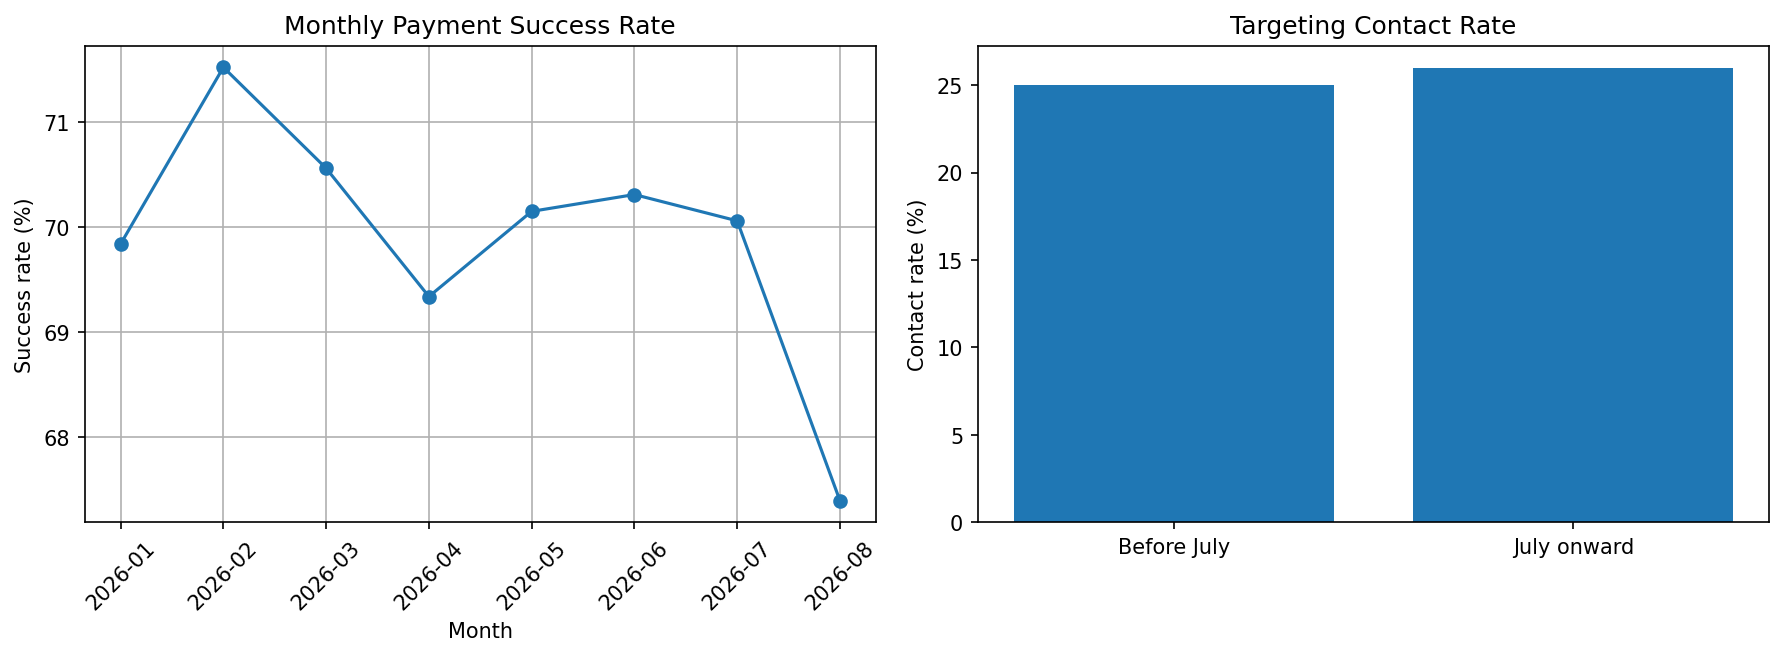

In [17]:
from IPython.display import Image, display
from pathlib import Path

chart_path = Path("submission/dashboard_charts.png")

print("Image size in bytes:", chart_path.stat().st_size)
display(Image(filename=str(chart_path)))

In [19]:
from pathlib import Path
import base64
import re

dashboard_path = Path("submission/executive_dashboard.html")
chart_path = Path("submission/dashboard_charts.png")

html = dashboard_path.read_text(encoding="utf-8")
image_data = base64.b64encode(chart_path.read_bytes()).decode("ascii")

html = re.sub(
    r'<img([^>]*?)src=["\']dashboard_charts\.png["\']',
    lambda match: f'<img{match.group(1)}src="data:image/png;base64,{image_data}"',
    html
)

dashboard_path.write_text(html, encoding="utf-8")

print("Dashboard updated successfully.")

Dashboard updated successfully.


In [21]:
from pathlib import Path
from datetime import datetime

zip_path = Path("collections_assignment_submission.zip")

if zip_path.exists():
    print("ZIP exists: Yes")
    print("Size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))
    print("Last updated:", datetime.fromtimestamp(
        zip_path.stat().st_mtime
    ).strftime("%d %b %Y, %I:%M %p"))
else:
    print("ZIP exists: No")

ZIP exists: Yes
Size (MB): 16.24
Last updated: 27 Oct 2026, 10:51 AM


In [23]:
from pathlib import Path
import zipfile

project_path = Path.cwd()
submission_path = project_path / "submission"
zip_path = project_path / "collections_assignment_submission.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in submission_path.rglob("*"):
        if file.is_file():
            zf.write(file, file.relative_to(project_path))

with zipfile.ZipFile(zip_path, "r") as zf:
    files = zf.namelist()

print("ZIP rebuilt successfully.")
print("Total files:", len(files))
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))
print("\nKey deliverables:")
for name in [
    "submission/executive_dashboard.html",
    "submission/reports/executive_memo.docx",
    "submission/data_quality_report.csv",
    "submission/golden_payments.csv",
    "submission/sql/collections_analysis.sql",
    "submission/data_architecture.mmd",
    "submission/README.md",
]:
    print(("FOUND: " if name in files else "MISSING: ") + name)

ZIP rebuilt successfully.
Total files: 32
ZIP size (MB): 16.3

Key deliverables:
FOUND: submission/executive_dashboard.html
FOUND: submission/reports/executive_memo.docx
FOUND: submission/data_quality_report.csv
FOUND: submission/golden_payments.csv
FOUND: submission/sql/collections_analysis.sql
FOUND: submission/data_architecture.mmd
FOUND: submission/README.md


In [25]:
from pathlib import Path
import zipfile
import hashlib

project_path = Path.cwd()
submission_path = project_path / "submission"
zip_path = project_path / "collections_assignment_submission.zip"

required_files = [
    "01_dataset_inspection.ipynb",
    "dashboard_charts.png",
    "data_architecture.mmd",
    "data_quality_report.csv",
    "executive_dashboard.html",
    "golden_payments.csv",
    "monthly_recovery_analysis.csv",
    "monthly_risk_analysis.csv",
    "targeting_comparison.csv",
    "README.md",
    "reports/executive_memo.docx",
    "sql/collections_analysis.sql",
    "golden_dataset/build_golden_dataset.py",
    "golden_dataset/data/payments_clean.csv",
    "golden_dataset/data/accounts_clean.csv",
    "golden_dataset/data/borrowers_clean.csv",
    "golden_dataset/data/pipeline_quality_report.csv"
]

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print("ZIP EXISTS:", zip_path.exists())

if zip_path.exists():
    with zipfile.ZipFile(zip_path, "r") as zf:
        bad_file = zf.testzip()
        zip_names = set(zf.namelist())

        print("ZIP INTEGRITY:", "PASS" if bad_file is None else f"FAIL: {bad_file}")
        print("FILES IN ZIP:", len(zip_names))

        print("\nREQUIRED FILES:")
        for name in required_files:
            archive_name = "submission/" + name
            print(
                ("FOUND: " if archive_name in zip_names else "MISSING: ")
                + archive_name
            )

print("\nNOTEBOOK COMPARISON:")

original_notebook = project_path / "01_dataset_inspection.ipynb"
submitted_notebook = submission_path / "01_dataset_inspection.ipynb"

if original_notebook.exists() and submitted_notebook.exists():
    print("Original notebook:", original_notebook.stat().st_size, "bytes")
    print("Submission notebook:", submitted_notebook.stat().st_size, "bytes")
    print(
        "Identical contents:",
        file_hash(original_notebook) == file_hash(submitted_notebook)
    )
else:
    print("One or both notebook files are missing.")

print("\nDASHBOARD EMBED CHECK:")

dashboard_path = submission_path / "executive_dashboard.html"

if dashboard_path.exists():
    html = dashboard_path.read_text(encoding="utf-8")
    print("Embedded chart:", "data:image/png;base64," in html)

ZIP EXISTS: True
ZIP INTEGRITY: PASS
FILES IN ZIP: 32

REQUIRED FILES:
FOUND: submission/01_dataset_inspection.ipynb
FOUND: submission/dashboard_charts.png
FOUND: submission/data_architecture.mmd
FOUND: submission/data_quality_report.csv
FOUND: submission/executive_dashboard.html
FOUND: submission/golden_payments.csv
FOUND: submission/monthly_recovery_analysis.csv
FOUND: submission/monthly_risk_analysis.csv
FOUND: submission/targeting_comparison.csv
FOUND: submission/README.md
FOUND: submission/reports/executive_memo.docx
FOUND: submission/sql/collections_analysis.sql
FOUND: submission/golden_dataset/build_golden_dataset.py
FOUND: submission/golden_dataset/data/payments_clean.csv
FOUND: submission/golden_dataset/data/accounts_clean.csv
FOUND: submission/golden_dataset/data/borrowers_clean.csv
FOUND: submission/golden_dataset/data/pipeline_quality_report.csv

NOTEBOOK COMPARISON:
Original notebook: 890057 bytes
Submission notebook: 499062 bytes
Identical contents: False

DASHBOARD EMBED

In [27]:
from pathlib import Path
import shutil
import hashlib

original = Path("01_dataset_inspection.ipynb")
submitted = Path("submission/01_dataset_inspection.ipynb")

shutil.copy2(original, submitted)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print("Submission notebook updated.")
print("Original size:", original.stat().st_size)
print("Submission size:", submitted.stat().st_size)
print("Identical contents:", sha256(original) == sha256(submitted))

Submission notebook updated.
Original size: 890057
Submission size: 890057
Identical contents: True


In [29]:
from pathlib import Path
import zipfile

project_path = Path.cwd()
submission_path = project_path / "submission"
zip_path = project_path / "collections_assignment_submission.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in submission_path.rglob("*"):
        if file.is_file():
            zf.write(file, file.relative_to(project_path))

with zipfile.ZipFile(zip_path, "r") as zf:
    names = zf.namelist()
    notebook_name = "submission/01_dataset_inspection.ipynb"
    notebook_in_zip = zf.read(notebook_name)

print("ZIP rebuilt.")
print("Total files:", len(names))
print(
    "Notebook in ZIP matches current notebook:",
    notebook_in_zip == Path("01_dataset_inspection.ipynb").read_bytes()
)
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))
print("ZIP integrity:", "PASS" if zipfile.ZipFile(zip_path).testzip() is None else "FAIL")

ZIP rebuilt.
Total files: 32
Notebook in ZIP matches current notebook: True
ZIP size (MB): 16.4
ZIP integrity: PASS


In [31]:
from docx import Document
from pathlib import Path

memo_path = Path("submission/reports/executive_memo.docx")
doc = Document(memo_path)

print("Memo exists:", memo_path.exists())
print("Paragraphs:", len(doc.paragraphs))
print("Tables:", len(doc.tables))

for paragraph in doc.paragraphs:
    if paragraph.text.strip():
        print(paragraph.text)

Memo exists: True
Paragraphs: 14
Tables: 0
Collections Performance: Executive Memo
Decision brief | Analysis period: January–August 8, 2026
1. What happened?
The available payment data does not show a consistent month-on-month improvement in payment success rate. The rate was 69.84% in January, peaked at 71.52% in February, and was 70.06% in July. August's observed rate was 67.40%, but the dataset only runs through August 8 and should not be compared directly with complete months.
2. What may explain the pattern?
Initial portfolio and targeting analyses show differences across risk segments and communication channels, but they do not establish causation. Targeting contact rates were broadly similar across channels before July and from July onward. More analysis is needed to test portfolio mix, campaign attribution, agent performance, and targeting effects.
3. Data quality and confidence
The raw payment table contains 25,500 rows. Exact-row deduplication removed 486 excess rows, leaving

In [33]:
from pathlib import Path
from docx import Document

memo_path = Path("submission/reports/executive_memo.docx")
doc = Document(memo_path)

print("Section count:", len(doc.sections))

for i, section in enumerate(doc.sections, start=1):
    print(
        f"Section {i}: page size "
        f"{section.page_width / 914400:.2f} x "
        f"{section.page_height / 914400:.2f} inches"
    )

print("\nManual page breaks:", sum(
    paragraph._p.xml.count('w:type="page"')
    for paragraph in doc.paragraphs
))

Section count: 1
Section 1: page size 8.50 x 11.00 inches

Manual page breaks: 0


In [35]:
from pathlib import Path
import subprocess

project_path = Path.cwd()

result = subprocess.run(
    ["git", "rev-parse", "--show-toplevel"],
    cwd=project_path,
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("Git repository found:", result.stdout.strip())
else:
    print("No Git repository found at the project root.")

print("\nGit installed:")
version = subprocess.run(
    ["git", "--version"],
    capture_output=True,
    text=True
)
print(version.stdout.strip() if version.returncode == 0 else "Not available")

No Git repository found at the project root.

Git installed:
git version 2.45.1.windows.1


In [37]:
from pathlib import Path
import subprocess

project_path = Path.cwd()

result = subprocess.run(
    ["git", "rev-parse", "--show-toplevel"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("Git repository:", result.stdout.strip() if result.returncode == 0 else "Not found")

version = subprocess.run(
    ["git", "--version"],
    capture_output=True,
    text=True
)

print("Git installed:", version.stdout.strip() if version.returncode == 0 else "No")

Git repository: Not found
Git installed: git version 2.45.1.windows.1


In [39]:
from pathlib import Path
import subprocess

project_path = Path.cwd()

result = subprocess.run(
    ["git", "init"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Initialized empty Git repository in C:/Users/keert/OneDrive/Documents/Data-Analyst-Assignment/.git/




In [41]:
from pathlib import Path

gitignore_path = Path(".gitignore")

gitignore_path.write_text(
    "__pycache__/\n"
    "*.py[cod]\n"
    ".ipynb_checkpoints/\n"
    ".DS_Store\n",
    encoding="utf-8"
)

print(".gitignore created.")

.gitignore created.


In [43]:
import subprocess

subprocess.run(["git", "add", "submission", "golden_dataset", "outputs", ".gitignore", "01_dataset_inspection.ipynb"], check=True)

result = subprocess.run(
    ["git", "commit", "-m", "Complete collections performance analysis assignment"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

[master (root-commit) 2cd4c05] Complete collections performance analysis assignment
 56 files changed, 1339318 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 01_dataset_inspection.ipynb
 create mode 100644 golden_dataset/build_golden_dataset.py
 create mode 100644 golden_dataset/data/account_status_history_clean.csv
 create mode 100644 golden_dataset/data/accounts_clean.csv
 create mode 100644 golden_dataset/data/agent_sessions_clean.csv
 create mode 100644 golden_dataset/data/agents_clean.csv
 create mode 100644 golden_dataset/data/borrowers_clean.csv
 create mode 100644 golden_dataset/data/call_attempts_clean.csv
 create mode 100644 golden_dataset/data/call_dispositions_clean.csv
 create mode 100644 golden_dataset/data/calls_clean.csv
 create mode 100644 golden_dataset/data/campaigns_clean.csv
 create mode 100644 golden_dataset/data/complaints_clean.csv
 create mode 100644 golden_dataset/data/daily_targeting_clean.csv
 create mode 100644 golden_dataset/data/field_vi

In [45]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short"],
    capture_output=True,
    text=True
)

print("Working tree:", "Clean" if not result.stdout.strip() else "Changes detected")
print(result.stdout if result.stdout.strip() else "No uncommitted changes.")

Working tree: Changes detected
 M 01_dataset_inspection.ipynb
?? collections_assignment_submission.zip
?? data/



In [47]:
from pathlib import Path
import zipfile

project_path = Path.cwd()
submission_path = project_path / "submission"
zip_path = project_path / "collections_assignment_submission.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in submission_path.rglob("*"):
        if file.is_file():
            zf.write(file, file.relative_to(project_path))

with zipfile.ZipFile(zip_path, "r") as zf:
    print("ZIP integrity:", "PASS" if zf.testzip() is None else "FAIL")
    print("Files packaged:", len(zf.namelist()))
    print(
        "Notebook synchronized:",
        zf.read("submission/01_dataset_inspection.ipynb")
        == Path("01_dataset_inspection.ipynb").read_bytes()
    )

print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

ZIP integrity: PASS
Files packaged: 33
Notebook synchronized: False
ZIP size (MB): 16.4
